APRENDIZAJE NO SUPERVISADO (DengAI)<center>

---
# Resumen
---

En este notebook analizamos el dataset de DengAI mediante aprendizaje no supervisado para identificar y caracterizar los patrones climáticos de San Juan e Iquitos. El proyecto se estructuró en cuatro fases: Exploración general del dataset, así como la distribución y naturaleza de los datos. Un preprocesamiento enfocado en imputar nulos por estacionalidad, eliminar redundancias y corregir el sesgo de las lluvias con la transformación de Yeo-Johnson y escalado estándar; una etapa de experimentación evaluando cuatro algoritmos (Jerárquico Ward, K-Means++, DBSCAN y GMM) mediante métricas de Silueta, Davies-Bouldin y proyecciones 2D en PCA; y la evaluación final de agrupamientos. Los resultados confirmaron que $k=3$ es la división óptima al separar la masa estable y selvática de Iquitos de las dos estaciones climáticas de San Juan (seca y lluviosa), destacando K-Means++ como el mejor clasificador global.

La competición de DengAI de DrivenData se podrá consultar en el siguiente enlace así como el dataset correspondiente: https://www.drivendata.org/competitions/44/dengai-predicting-disease-spread/

---
# Inicialización
---

In [1]:
# Imports generales
import pandas as pd
import numpy as np
import io
from google.colab import files
import matplotlib.pyplot as plt
import seaborn as sns
import math
from scipy.stats import skew
from sklearn.preprocessing import PowerTransformer, StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import davies_bouldin_score, silhouette_score
from scipy.cluster.hierarchy import cophenet, linkage
from scipy.spatial.distance import pdist
from sklearn.cluster import KMeans
from sklearn.neighbors import NearestNeighbors
from sklearn.cluster import DBSCAN
from sklearn.mixture import GaussianMixture



seed = 42  # Semilla aleatoria arbitraria y constante a incluir en los algoritmos estocásticos para que los experimentos sean siempre reproducibles por el profesor.
# En los experimentos estocásticos que requieran varias iteraciones con distintas semillas, podéis incorporarla como seed+1, seed+2, etc.

def upload_files (index_fields=None):
  uploaded = files.upload()
  for fn in uploaded.keys():
    print('User uploaded file "{name}" with length {length} bytes'.format(
        name=fn, length=len(uploaded[fn])))
    df = pd.read_csv(io.StringIO(uploaded[fn].decode('utf-8')), index_col = index_fields)
    return df

In [2]:
# Subir el conjunto de entrenamiento sin variable objetivo (dengue_features_train.csv)
train = upload_files()
print(train.shape)
train.head()

Saving dengue_features_train.csv to dengue_features_train (4).csv
User uploaded file "dengue_features_train (4).csv" with length 287139 bytes
(1456, 24)


,city,year,weekofyear,week_start_date,ndvi_ne,ndvi_nw,ndvi_se,ndvi_sw,precipitation_amt_mm,reanalysis_air_temp_k,...,reanalysis_precip_amt_kg_per_m2,reanalysis_relative_humidity_percent,reanalysis_sat_precip_amt_mm,reanalysis_specific_humidity_g_per_kg,reanalysis_tdtr_k,station_avg_temp_c,station_diur_temp_rng_c,station_max_temp_c,station_min_temp_c,station_precip_mm
0,sj,1990,18,1990-04-30,0.122600,0.103725,0.198483,0.177617,12.42,297.572857,...,32.00,73.365714,12.42,14.012857,2.628571,25.442857,6.900000,29.4,20.0,16.0
1,sj,1990,19,1990-05-07,0.169900,0.142175,0.162357,0.155486,22.82,298.211429,...,17.94,77.368571,22.82,15.372857,2.371429,26.714286,6.371429,31.7,22.2,8.6
2,sj,1990,20,1990-05-14,0.032250,0.172967,0.157200,0.170843,34.54,298.781429,...,26.10,82.052857,34.54,16.848571,2.300000,26.714286,6.485714,32.2,22.8,41.4
3,sj,1990,21,1990-05-21,0.128633,0.245067,0.227557,0.235886,15.36,298.987143,...,13.90,80.337143,15.36,16.672857,2.428571,27.471429,6.771429,33.3,23.3,4.0
4,sj,1990,22,1990-05-28,0.196200,0.262200,0.251200,0.247340,7.52,299.518571,...,12.20,80.460000,7.52,17.210000,3.014286,28.942857,9.371429,35.0,23.9,5.8


---
# Exploración
---

Con el fin de comprender el dataset en su totalidad en este enlace se puede ver una descripción de qué significan las características del dataset: https://www.drivendata.org/competitions/44/dengai-predicting-disease-spread/page/82/

## Verificación de Tipos, Nulos y Duplicados
Antes de realizar cualquier transformación, es importante conocer la estructura del conjunto de datos. En esta sección verificaremos los tipos de datos de cada variable, cuantificaremos la cantidad de valores nulos presentes y comprobaremos si existen registros duplicados que puedan sesgar el análisis.

In [3]:
# Verificación de la estructura y tipos de datos
print("=== INFORMACIÓN DEL DATASET ===")
train.info()

print("\n=== VALORES NULOS POR COLUMNA ===")
# Filtramos solo las columnas que tienen nulos
nulos = train.isnull().sum() #Suma de nulos por variable
print(nulos[nulos > 0].sort_values(ascending=False))

print("\n=== REGISTROS DUPLICADOS ===")
duplicados = train.duplicated().sum()
print(f"Total de filas duplicadas: {duplicados}")

=== INFORMACIÓN DEL DATASET ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1456 entries, 0 to 1455
Data columns (total 24 columns):
 #   Column                                 Non-Null Count  Dtype  
---  ------                                 --------------  -----  
 0   city                                   1456 non-null   object 
 1   year                                   1456 non-null   int64  
 2   weekofyear                             1456 non-null   int64  
 3   week_start_date                        1456 non-null   object 
 4   ndvi_ne                                1262 non-null   float64
 5   ndvi_nw                                1404 non-null   float64
 6   ndvi_se                                1434 non-null   float64
 7   ndvi_sw                                1434 non-null   float64
 8   precipitation_amt_mm                   1443 non-null   float64
 9   reanalysis_air_temp_k                  1446 non-null   float64
 10  reanalysis_avg_temp_k                  1

**Análisis de tipos**
- **Tipo de variable:** La variable `week_start_date` debería ser de tipo Date, razón por la cual vamos a realizar la transformación de inmediato. Además dado que en San Juan e Iquitos no existen estaciones, vamos a generar una nueva variable que se llame mes. El mes es lineal y los meses se representan mejor de manera cíclica, por lo que podemos aplicar una función seno y coseno al mes, para que las fechas queden ciclicas y por ejemplo enero y diciembre estén realmente cerca.

- **Duplicados:** No tenemos valores nulos en este dataset

- **Nulos:** Multiples columnas presentan valores nulos, por lo que tendremos que realizar un proceso de imputación posterior, teniendo en cuenta que al ser variables climatológicas en su mayoría, debemos realizarlo por región y temporalidad.

In [4]:
# Convertir la columna 'week_start_date' de objeto a datetime
train['week_start_date'] = pd.to_datetime(train['week_start_date'])

# Extraer el número de mes (valores del 1 al 12)
train['mes'] = train['week_start_date'].dt.month

# Aplicar la transformación cíclica (Seno y Coseno)
train['mes_sin'] = np.sin(2 * np.pi * train['mes'] / 12)
train['mes_cos'] = np.cos(2 * np.pi * train['mes'] / 12)

In [5]:
#Visión preliminar de las instancias presentes en el dataset
train.describe(include="all").T

,count,unique,top,freq,mean,min,25%,50%,75%,max,std
city,1456,2,sj,936,NaN,NaN,NaN,NaN,NaN,NaN,NaN
year,1456.0,NaN,NaN,NaN,2001.031593,1990.0,1997.0,2002.0,2005.0,2010.0,5.408314
weekofyear,1456.0,NaN,NaN,NaN,26.503434,1.0,13.75,26.5,39.25,53.0,15.019437
week_start_date,1456,NaN,NaN,NaN,2001-07-09 16:01:19.120879104,1990-04-30 00:00:00,1997-04-28 06:00:00,2002-05-28 00:00:00,2005-11-26 00:00:00,2010-06-25 00:00:00,NaN
ndvi_ne,1262.0,NaN,NaN,NaN,0.142294,-0.40625,0.04495,0.128817,0.248483,0.508357,0.140531
ndvi_nw,1404.0,NaN,NaN,NaN,0.130553,-0.4561,0.049217,0.121429,0.2166,0.454429,0.119999
ndvi_se,1434.0,NaN,NaN,NaN,0.203783,-0.015533,0.155087,0.19605,0.248846,0.538314,0.07386
ndvi_sw,1434.0,NaN,NaN,NaN,0.202305,-0.063457,0.144209,0.18945,0.246982,0.546017,0.083903
precipitation_amt_mm,1443.0,NaN,NaN,NaN,45.760388,0.0,9.8,38.34,70.235,390.6,43.715537
reanalysis_air_temp_k,1446.0,NaN,NaN,NaN,298.701852,294.635714,297.658929,298.646429,299.833571,302.2,1.36242


## Análisis de Distribuciones
Para comprender la distribución de los datos y evaluar el comportamiento de las variables, se generan histogramas diferenciados por ciudad (`sj` e `iq`). Esta inspección visual permite identificar la simetría, el sesgo y la presencia de multimodalidad entre San Juan e Iquitos.


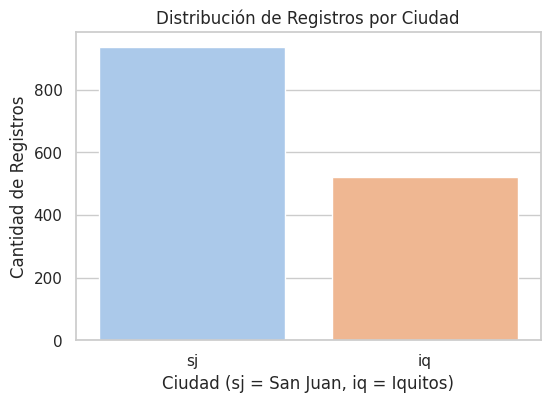

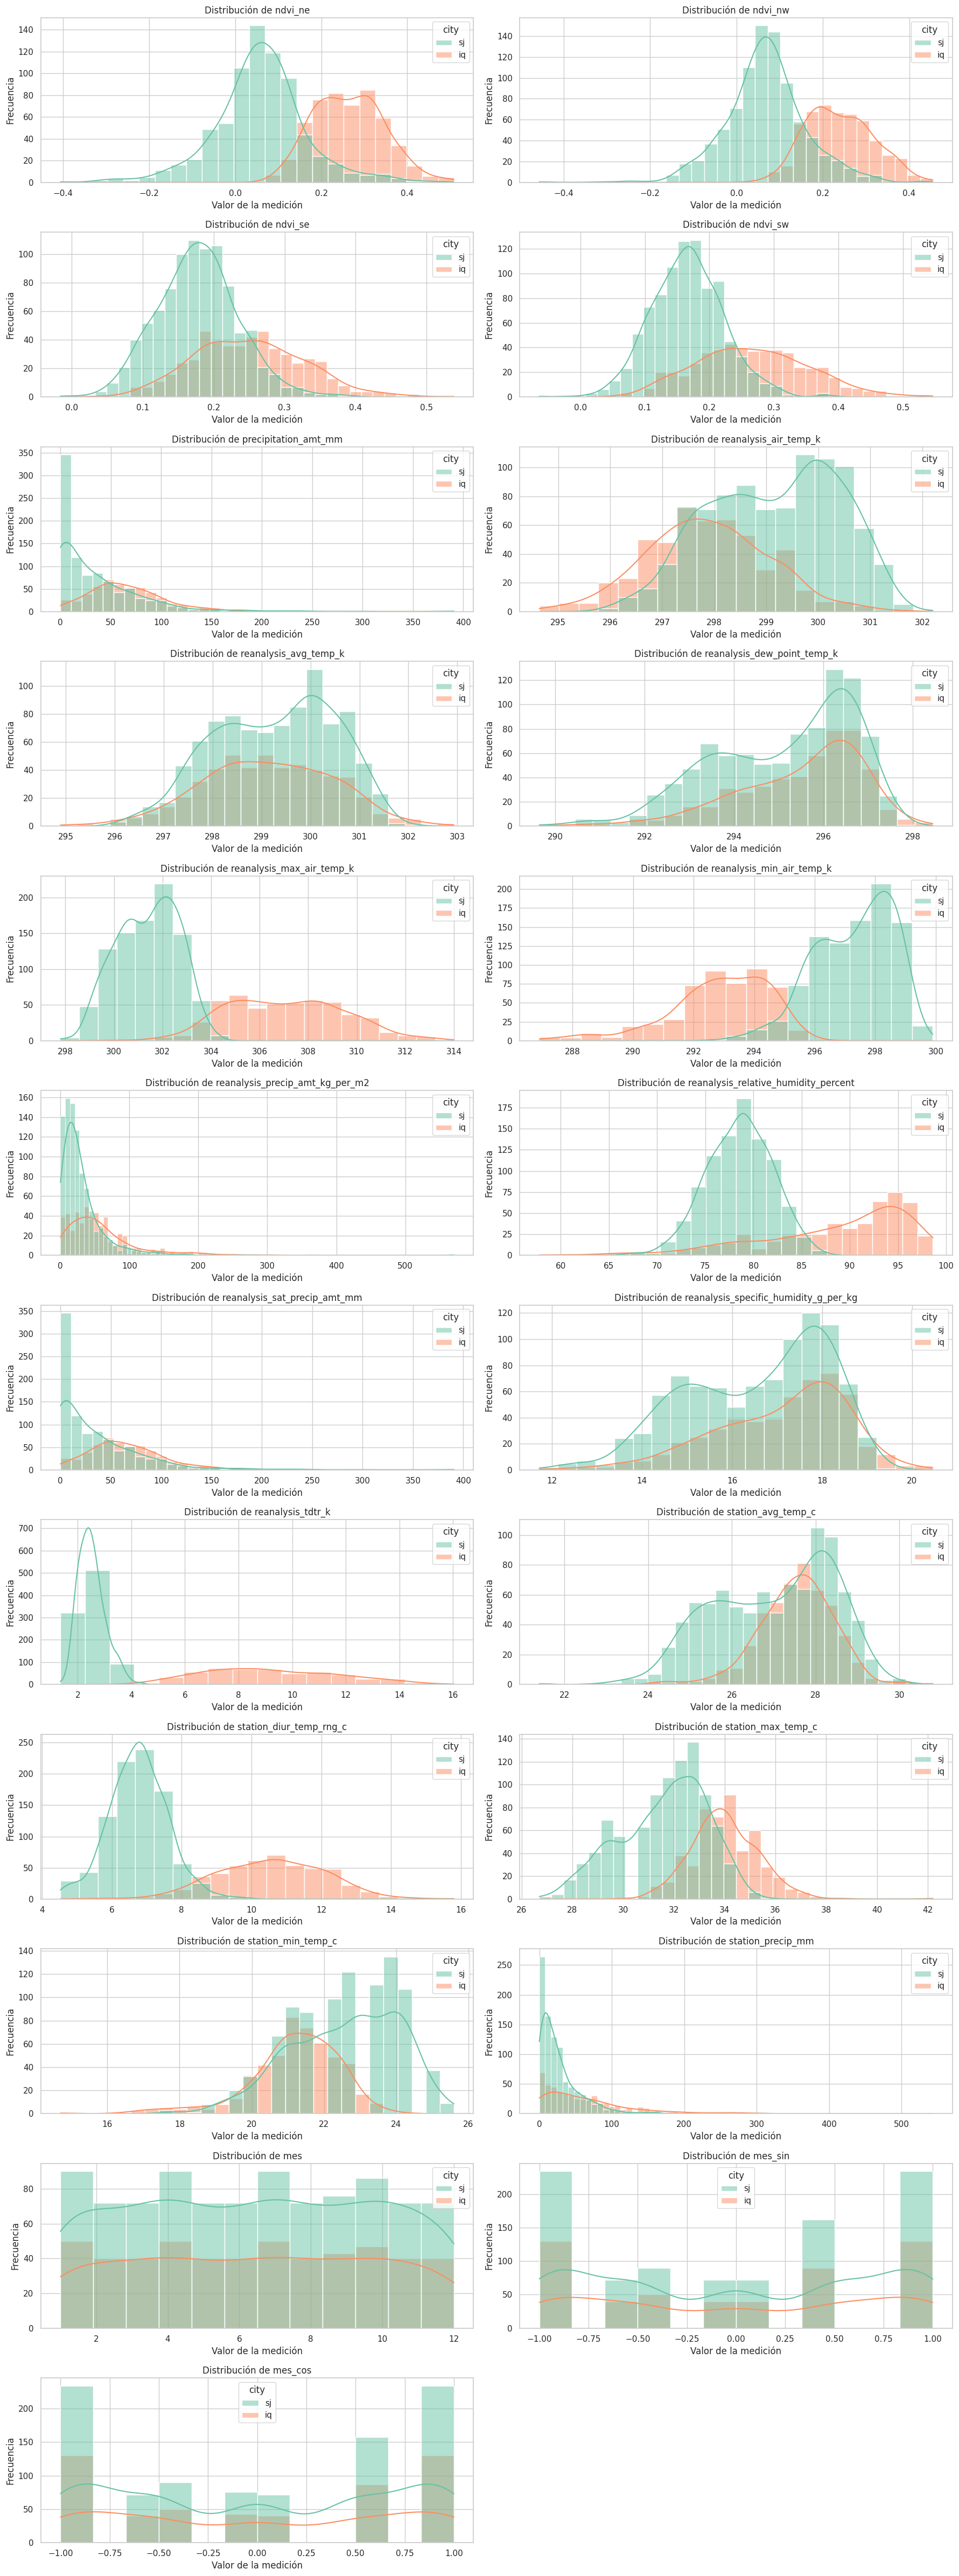

In [6]:
# Configuración del estilo de todos los gráficos
sns.set_theme(style="whitegrid")

# Gráfico de barras para la variable categórica (city)
plt.figure(figsize=(6, 4))
sns.countplot(data=train, x='city', hue='city', palette='pastel', legend=False)
plt.title('Distribución de Registros por Ciudad')
plt.xlabel('Ciudad (sj = San Juan, iq = Iquitos)')
plt.ylabel('Cantidad de Registros')
plt.show()

# Histogramas para todas las variables numéricas
# Filtramos las columnas numéricas y excluimos los identificadores temporales
cols_numericas = train.select_dtypes(include=[np.number]).columns.tolist()
cols_hist = [col for col in cols_numericas if col not in ['year', 'weekofyear']]

# Calculamos el tamaño de la cuadrícula (2 columnas y las filas necesarias)
n_cols = 2
n_rows = math.ceil(len(cols_hist) / n_cols)

# Creamos el gráfico ajustando el tamaño dinámicamente
fig, axes = plt.subplots(n_rows, n_cols, figsize=(18, 4 * n_rows))
axes = axes.flatten() # Aplanamos la matriz de gráficos para iterar más fácil

for i, col in enumerate(cols_hist):
    # Graficamos cada variable diferenciando por ciudad
    sns.histplot(data=train, x=col, hue='city', kde=True, ax=axes[i], palette='Set2')
    axes[i].set_title(f'Distribución de {col}')
    axes[i].set_xlabel('Valor de la medición')
    axes[i].set_ylabel('Frecuencia')

# Eliminamos espacios sobrantes en la cuadrícula
for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

**Interpretación de las Distribuciones**

* **Diferenciación Microclimática y Vegetación:**  Es notable la diferencia en la vegetación entre San Juan e iquitos, ya que podemos observar como los datos en iIuitos se ubican mayormente a la derecha en comparación con San Juan, esto concuerda con su ubicación geográfica, ya que San Juan es una isla e iquitos se encuentra en la mitad de la selva Amazónica. Asimismo, variables como el rango de temperatura diurna y la humedad relativa muestran distribuciones notablemente más amplias e intensas en Iquitos, reflejando su clima ecuatorial amazónico frente al clima tropical marítimo de San Juan.

* **Sesgo en Precipitaciones:** Todas las métricas de lluvia exhiben un marcado sesgo a la derecha (asimetría positiva), con concentraciones altas en valores bajos y colas largas asociadas a eventos extremos de precipitación. Aunque iquitos tiene una menor asimetría ya que las lluvias son más recurrentes, igual sigue presentando una asimetría positiva.

* **Comportamiento Cíclico:** Las variables temporales transformadas (`mes_sin`, `mes_cos`) muestran distribuciones simétricas y acotadas entre -1 y 1. lo que nos confirma una correcta transformación, con pequeñas diferencias ocasionadas por la distribución de los meses en el dataset.

## Tratamiento de Duplicados y Nulos
Tras la revisión inicial, procedemos a limpiar el dataset. Como no existen valores duplicados omitimos esta fase del proceso. En cuanto a la imputación de los valores nulos, con el fin de mantener la distribución natural de los datos al ser datos climáticos, los imputaremos tomando en cuenta la mediana, agrupando los datos por ciudad (`city`) y semana del año (`weekofyear`). Esto garantiza que los valores rellenados respeten la estacionalidad local de San Juan e Iquitos.

In [7]:
# Imputación de nulos por medio de Mediana agrupada por ciudad y semana del año
# Identificamos las columnas numéricas con nulos
cols_con_nulos = nulos[nulos > 0].index.tolist()

for col in cols_con_nulos:
    # Agrupamos por ciudad y semana para mantener la coherencia climática y temporal
    train[col] = train.groupby(['city', 'weekofyear'])[col].transform(
        lambda x: x.fillna(x.median())
    )

print("\nVerificación de nulos tras la imputación:")
print(train.isnull().sum().sum(), "nulos restantes.")


Verificación de nulos tras la imputación:
100 nulos restantes.


In [8]:
# Filtrar y mostrar los registros que contienen al menos un valor nulo
filas_con_nulos = train[train.isnull().any(axis=1)]

print(f"Total de filas con al menos un valor nulo: {len(filas_con_nulos)}")

# Mostramos las primeras 10 filas para entender qué datos están faltando
display(filas_con_nulos.head(10))

# Mostrar la cantidad de registros con semana 53
print(f"Registros con semana 53: {len(train[train['weekofyear'] == 53])}")

Total de filas con al menos un valor nulo: 5


,city,year,weekofyear,week_start_date,ndvi_ne,ndvi_nw,ndvi_se,ndvi_sw,precipitation_amt_mm,reanalysis_air_temp_k,...,reanalysis_specific_humidity_g_per_kg,reanalysis_tdtr_k,station_avg_temp_c,station_diur_temp_rng_c,station_max_temp_c,station_min_temp_c,station_precip_mm,mes,mes_sin,mes_cos
139,sj,1993,53,1993-01-01,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1,0.5,0.866025
451,sj,1999,53,1999-01-01,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1,0.5,0.866025
763,sj,2005,53,2005-01-01,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1,0.5,0.866025
1170,iq,2005,53,2005-01-01,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1,0.5,0.866025
1430,iq,2010,53,2010-01-01,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1,0.5,0.866025


Registros con semana 53: 5


**Nulos semana 53:** Consultando se puede concluir que esto se debe a que en el candelario ISO el año consta de 52 o 53 semanas (https://docs.python.org/es/3.8/library/datetime.html, 2024), posiblemente en la recolección de los datos se asumió que todas las semanas tenían solo 52 semanas, por lo que la 53 quedó con valores vacios.

teniendo en cuenta que en este desarrollo no se realizarán análisis de series temporales y que todos los datos de la semana 53 (solo 5 registros) son nulos, no se imputarán los datos y por el contrario se van a eliminar para no generar ruido innecesario.

In [9]:
# Eliminamos los registros de la semana 53
train = train[train['weekofyear'] != 53].reset_index(drop=True)
print(f"Registros con semana 53: {len(train[train['weekofyear'] == 53])}")

Registros con semana 53: 0


## Identificación de Outliers
En el proceso de identificación de valores atípicos, usaremos diagramas de caja (boxplots). Nuevamente separaremos la visualización por ciudad, ya que los umbrales de lo que se considera "atípico" varían según la ubicación geográfica.

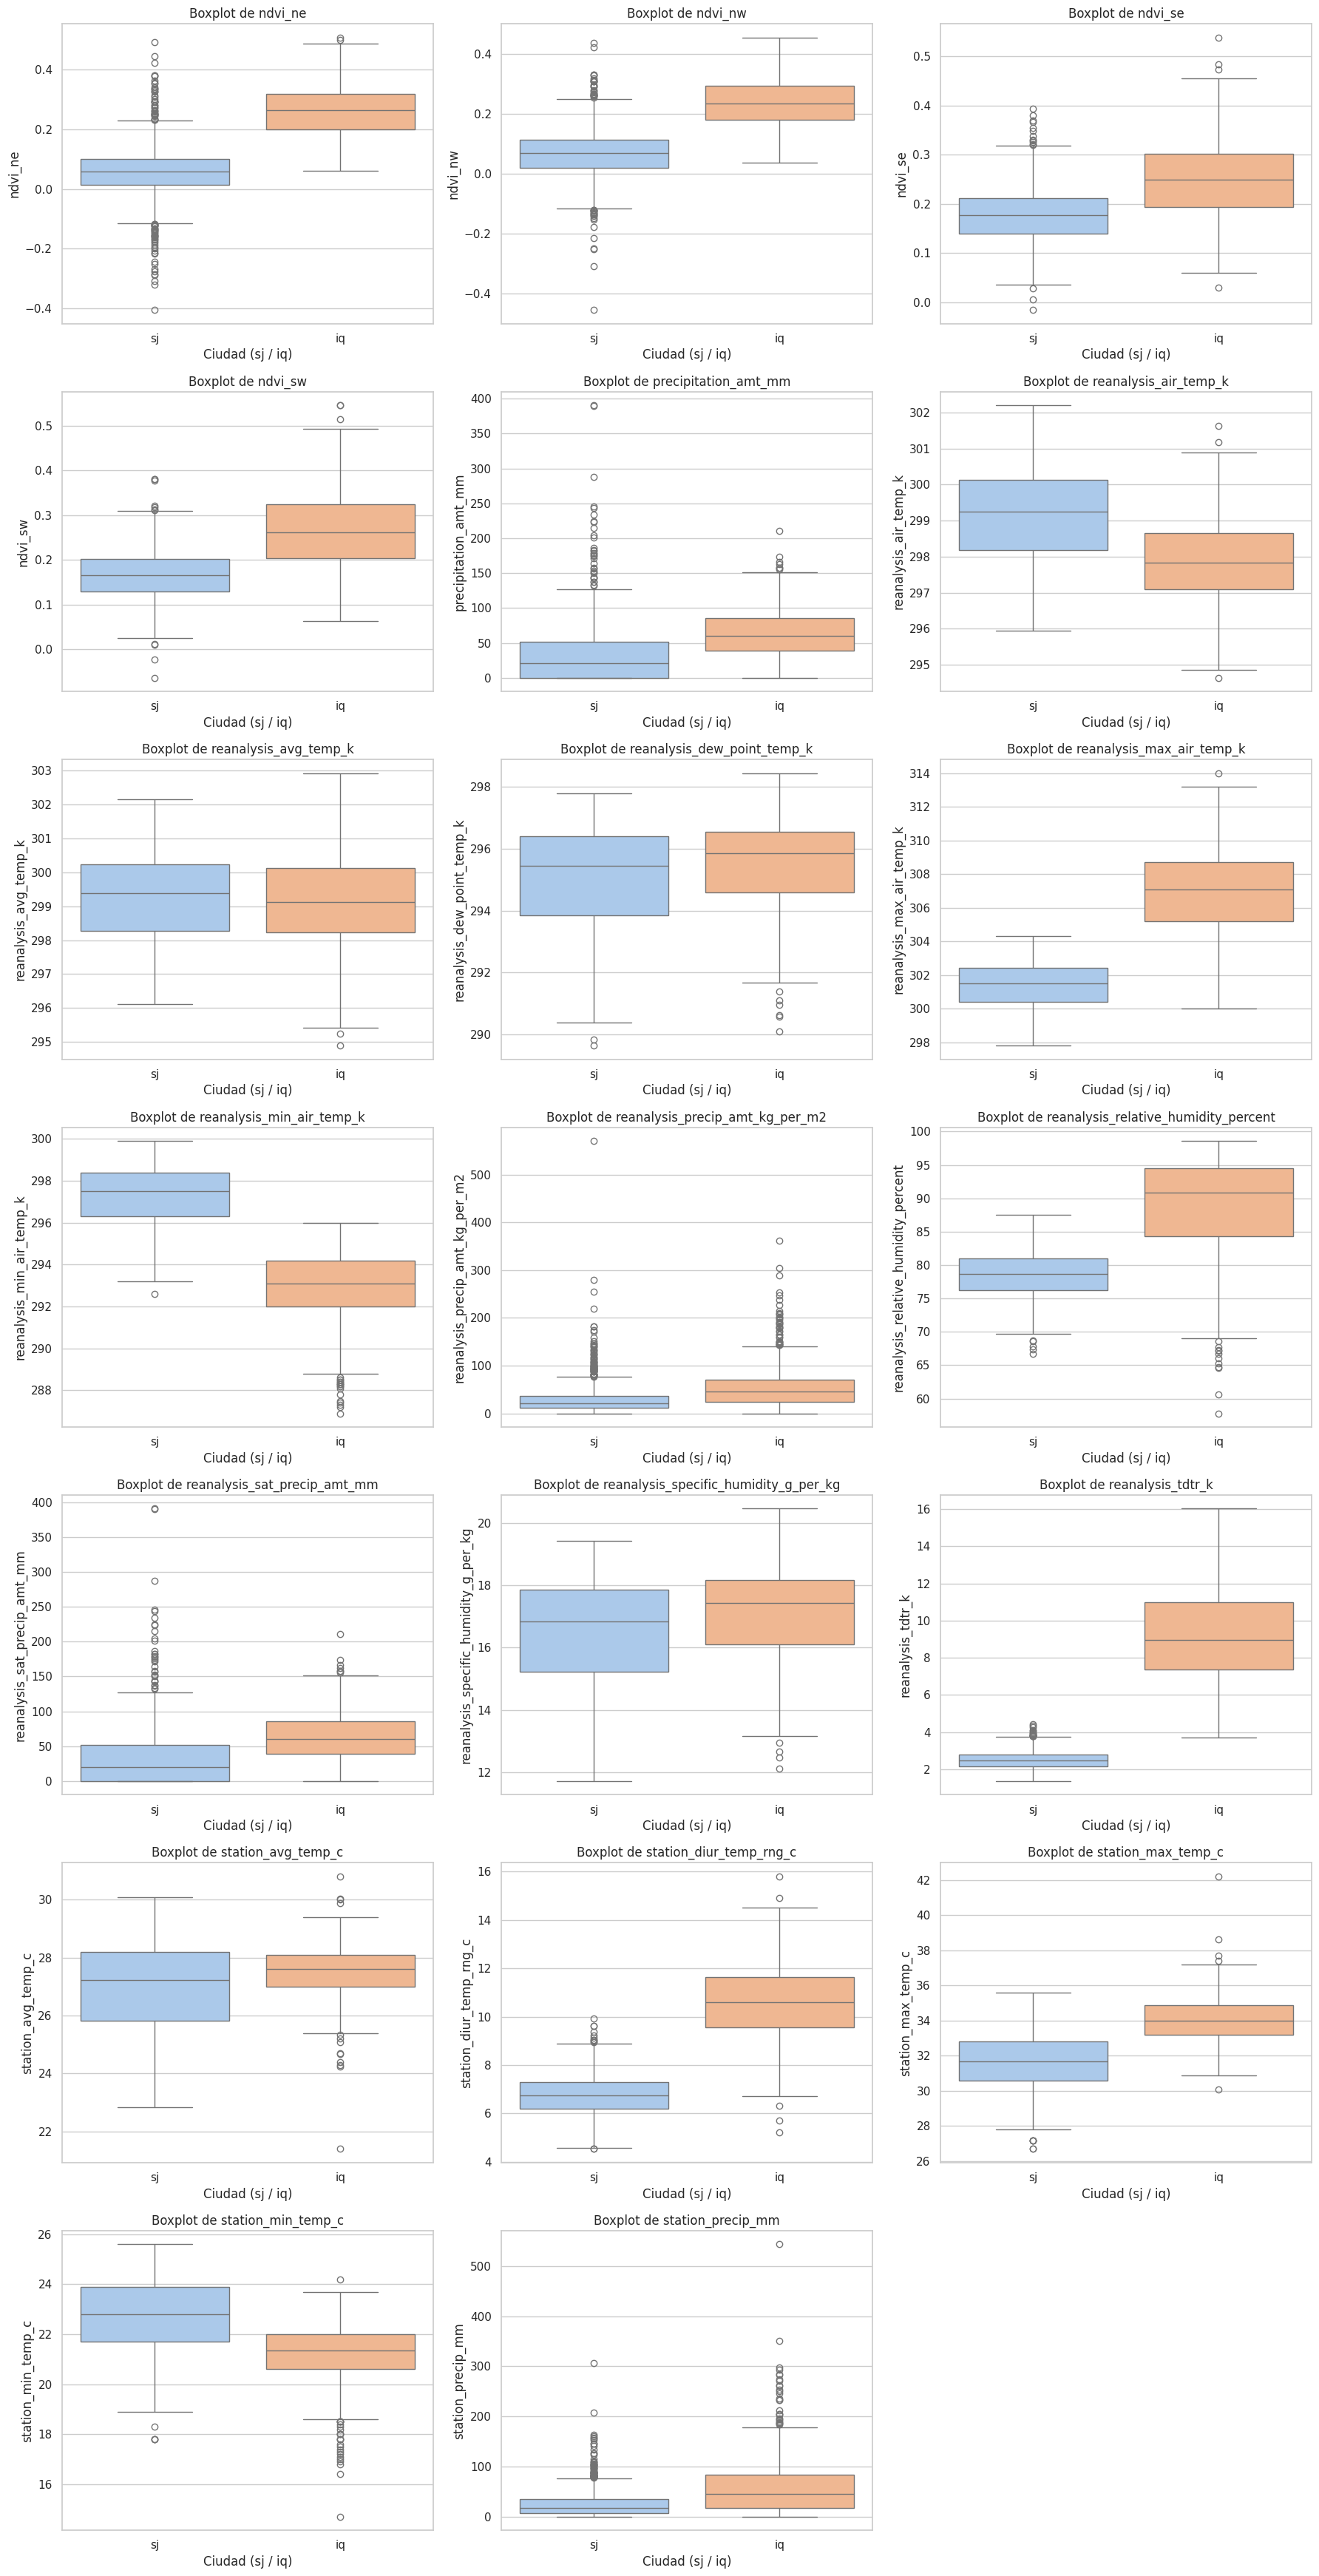

In [10]:
# Seleccionamos todas las numéricas y excluimos las variables temporales/cíclicas
cols_numericas = train.select_dtypes(include=[np.number]).columns.tolist()
cols_box = [col for col in cols_numericas if col not in ['year', 'weekofyear', 'mes', 'mes_sin', 'mes_cos']]

# Calculamos el tamaño de la cuadrícula
n_cols = 3
n_rows = math.ceil(len(cols_box) / n_cols)

# Creamos la figura dinámica
fig, axes = plt.subplots(n_rows, n_cols, figsize=(18, 5 * n_rows))
axes = axes.flatten()

for i, col in enumerate(cols_box):
    sns.boxplot(data=train, x='city', y=col, hue='city', ax=axes[i], palette='pastel', legend=False)
    axes[i].set_title(f'Boxplot de {col}')
    axes[i].set_xlabel('Ciudad (sj / iq)')
    axes[i].set_ylabel(col)

# Eliminamos los recuadros vacíos
for j in range(len(cols_box), len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

**Análisis de valores atípicos:**
Sí bien gran parte de los gráficos de bigotes muestran valores atípicos, son atípicos que en la naturaleza se encuentran en rangos normales.

**El NDVI** es el Índice de Vegetación de Diferencia Normalizada es un índice calculado con imágenes satelitales para determinar la salud de las plantas usando las bandas de rojo visible y el infrarojo cercano, información captada por medio de sensores remotos. (https://eos.com/es/blog/indice-de-vegetacion-de-diferencia-normalizada-o-ndvi/, 2026) Este NDVI es un valor en un rango de -1 a 1 siendo -1 sin vegetación y 1 bosques maduros en su totalidad. Sin embargo como profesional en Sistemas de Información Geográfica, puedo inferir que el NDVI al ser capturado con sensores remotos muchas veces se ven afectados por la presencia de nubes, las cuales disminuyen el valor del NDVI en general, sin embargo la presencia de nubes no es algo atípico, por lo que es normal que en los mismos meses o periodos de humedad se tenga una densidad similar de nubes. Es por esto que aunque el NDVi contiene valores atípicos, estos no se alejan de la realidad y es por esto que se decide mantener los valores como están.

**Precipitaciones** Las variables relacionadas con la precipitación tienen una gran concentración de valores cercanos a cero o cero absoluto, es por esto que los valores atípicos se presentan en valores altos, sin embargo nuevamente en valores normales en el contexto natural. Estas variables tampoco se modificaran para suavizar valores extremos, porque las fuentes de agua estancadas son criaderos de mosquitos, por lo tanto estos valores pueden darnos información crucial en nuestro ejercicio.

**Temperaturas** Al igual que con las precipitaciones se encuentra en rangos naturales que no amerita que se modifique, pues la temperatura también se relaciona con el ciclo reproductivo del dengue, ya que al ubicarse en zonas tropicales necesita unas condiciones adecuadas de temperatura y humedad, generalmente relacionado con temperaturas y humedad alta.



## Binarización variable categórica

Los algoritmos de aprendizaje no supervisado usan distancias geométricas en las n -dimensiones que tenga el dataset. Para adaptar la matriz de datos a este requerimiento matemático, aplicamos un proceso de binarización, ya que solo tenemos dos ciudades y podemos trabajar a sj como "1" e iq como "0". de esta manera vamos a poder tener en cuenta la ubicación geográfica como una variable en nuestro proceso de clasificación.

In [11]:
# Binarizador para la variable categórica city en el conjunto de entrenamiento y test
from sklearn import preprocessing
lb = preprocessing.LabelBinarizer()
train['city_bin'] = lb.fit_transform(train['city'])

train.sample(10)

,city,year,weekofyear,week_start_date,ndvi_ne,ndvi_nw,ndvi_se,ndvi_sw,precipitation_amt_mm,reanalysis_air_temp_k,...,reanalysis_tdtr_k,station_avg_temp_c,station_diur_temp_rng_c,station_max_temp_c,station_min_temp_c,station_precip_mm,mes,mes_sin,mes_cos,city_bin
423,sj,1998,26,1998-06-25,0.037450,0.016700,0.144700,0.152357,72.08,299.944286,...,2.357143,28.214286,6.742857,32.2,23.9,20.6,6,1.224647e-16,-1.000000e+00,1
1003,iq,2001,45,2001-11-05,0.358143,0.279343,0.305971,0.371400,34.54,298.514286,...,10.100000,27.525000,11.025000,34.4,21.3,35.1,11,-5.000000e-01,8.660254e-01,0
730,sj,2004,22,2004-05-27,-0.025633,-0.008067,0.159114,0.158800,175.41,298.365714,...,2.000000,24.814286,4.914286,28.9,21.7,145.8,5,5.000000e-01,-8.660254e-01,1
1071,iq,2003,9,2003-02-26,0.297600,0.236633,0.229150,0.207283,132.20,299.350000,...,9.114286,29.400000,11.200000,35.0,22.9,0.0,2,8.660254e-01,5.000000e-01,0
254,sj,1995,12,1995-03-26,0.031000,0.231650,0.207433,0.249714,0.00,296.480000,...,3.300000,24.628571,8.414286,31.7,18.9,2.3,3,1.000000e+00,6.123234e-17,1
883,sj,2007,20,2007-05-14,0.001900,0.012050,0.254414,0.237086,6.80,300.660000,...,3.171429,29.000000,7.671429,33.3,24.4,0.3,5,5.000000e-01,-8.660254e-01,1
164,sj,1993,26,1993-07-02,0.123767,0.152200,0.215414,0.218771,8.49,299.704286,...,2.000000,28.842857,5.871429,32.8,25.0,7.2,7,-5.000000e-01,-8.660254e-01,1
299,sj,1996,6,1996-02-05,0.027650,0.040750,0.164600,0.168686,0.00,297.307143,...,2.157143,25.157143,6.814286,29.4,21.1,10.8,2,8.660254e-01,5.000000e-01,1
814,sj,2006,2,2006-01-15,-0.042450,0.004550,0.259271,0.239314,72.69,298.332857,...,2.442857,24.057143,6.800000,27.8,18.9,21.9,1,5.000000e-01,8.660254e-01,1
1138,iq,2004,24,2004-06-10,0.237843,0.235083,0.166957,0.211971,85.28,295.574286,...,5.042857,26.800000,8.566667,32.0,20.9,87.9,6,1.224647e-16,-1.000000e+00,0


## Evolución temporal

Con el fin de comprender cómo se comportan las variables a través del tiempo y tener una mejor idea de las variables y su posible tendencia, examinamos sus series temporales diferenciadas por ciudad. Esto es necesario porque las dos ciudades presentan diferencias muy marcadas y no hacerlo podría enmascarar el comportamiento de la ciudad o generar ruido innecesari.

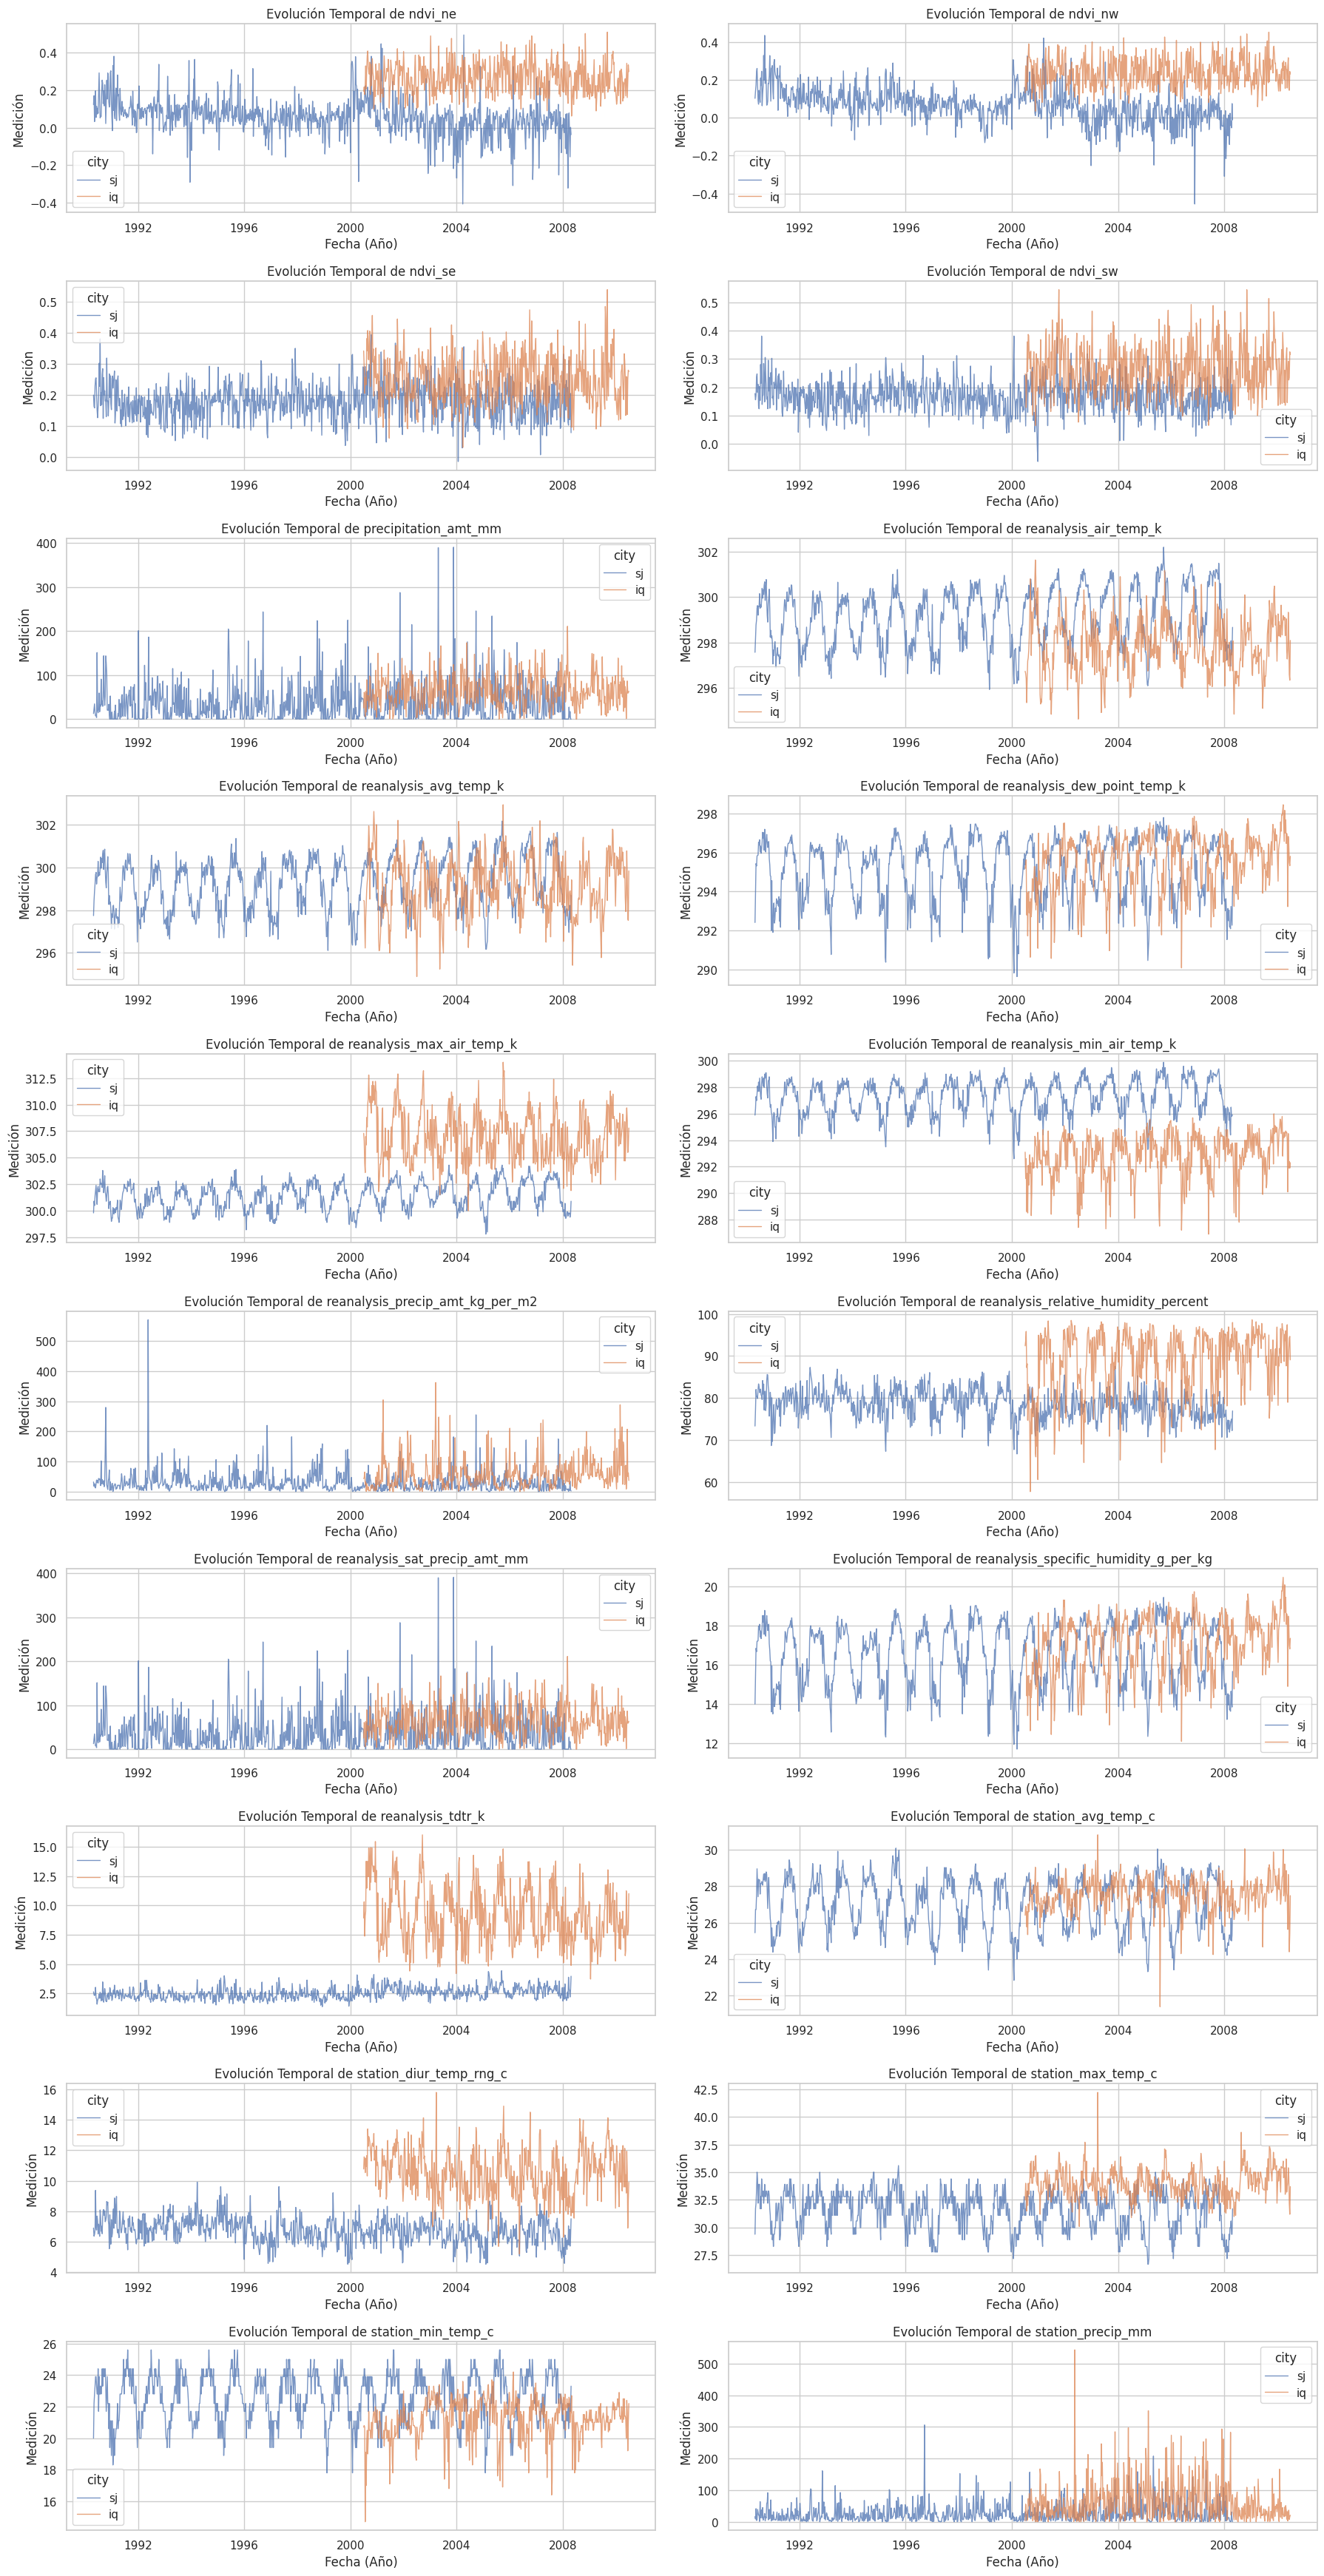

In [12]:
# Lista de variables numéricas continuas a graficar en el tiempo
cols_temporales = [
    c
    for c in train.select_dtypes(include=[np.number]).columns
    if c
    not in [
        'year',
        'weekofyear',
        'mes',
        'mes_sin',
        'mes_cos',
        'city_bin',
    ]
]

# Configuración de la cuadrícula
n_cols = 2
n_rows = math.ceil(len(cols_temporales) / n_cols)

fig, axes = plt.subplots(n_rows, n_cols, figsize=(18, 3.5 * n_rows))
axes = axes.flatten()

for i, col in enumerate(cols_temporales):
    sns.lineplot(
        data=train,
        x='week_start_date',
        y=col,
        hue='city',
        ax=axes[i],
        alpha=0.75,
        linewidth=1,
    )
    axes[i].set_title(f'Evolución Temporal de {col}')
    axes[i].set_xlabel('Fecha (Año)')
    axes[i].set_ylabel('Medición')

# Eliminamos celdas vacías si las hay
for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

**Análisis de evolución temporal de las variables**

- Diferenciación de la Cobertura Vegetal (NDVI): En las 4 diferentes mediciones se confirma la gran diferencia que existe entre las dos ciudades, ya que iquitos como bien lo analizamos tiene mayor vegetación, por lo que presenta valores mayores de NDVI. Por otro lado vemos las variaciones normales, dadas en la mayoría de los casos por humedad o nubes, ya que estos valores disminuyen considerablemente el valor del NDVI. Algo muy interesante que logramos notar es que las caidas del NDVI se relacionan con valores mayores en la precipitación confirmando la relación de la que hablamos.

- variables térmicas: Vemos como San Juan tiene variaciones mucho más marcadas que iquitos, lo que se ve de manera más clara en la variable de temperatura promedio, esto se debe posiblemente a la ubicación de iquitos sobre el ecuador, teniendo temperaturas más estables a lo largo del año.

- Variables de humedad y precipitación: Ambas series confirman que no existe una tendencia de aumento o disminución sostenida en el tiempo. Mientras que Iquitos mantiene un flujo de precipitación constante a lo largo del año, San Juan registra picos atípicos intermitentes de lluvia muy intensa. Nuevamente confirmamos la diferencia tan marcada que existe entre ambos en terminos de humedad y precipitación.

## Matriz de Correlación

Con el fin de comprender las relaciones existentes entre las variables realizamos la matriz de correlación

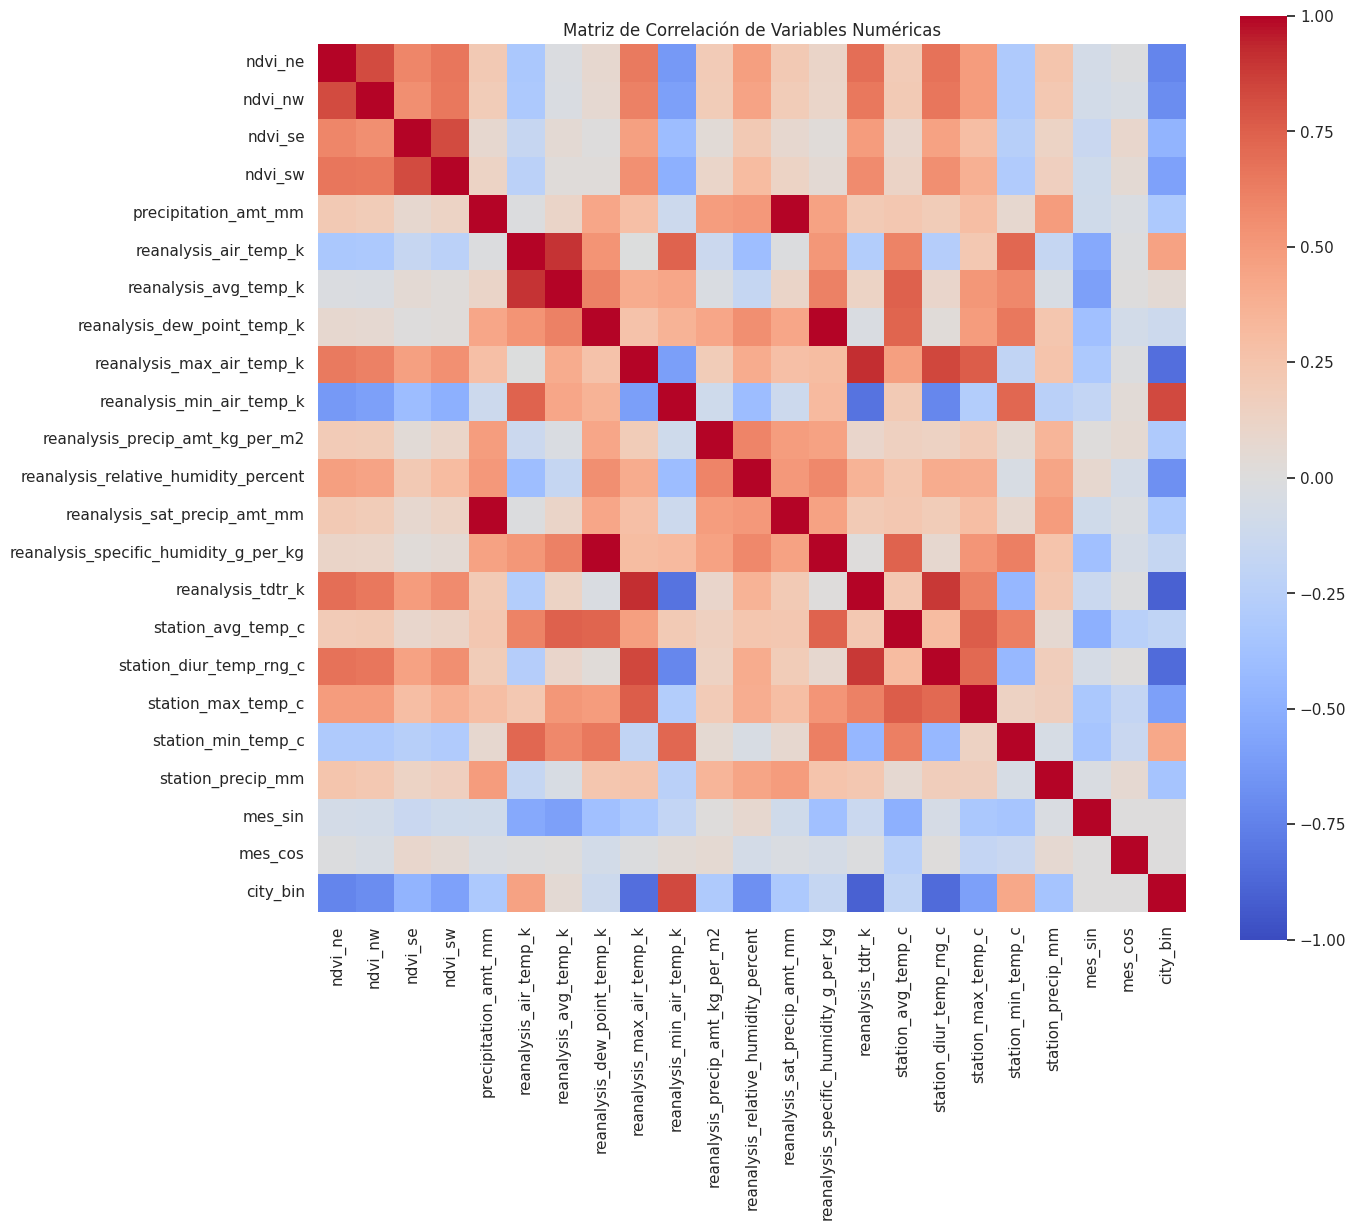

Variables con correlación muy alta (|r| > 0.90):
- precipitation_amt_mm y reanalysis_sat_precip_amt_mm: 1.0000
- reanalysis_dew_point_temp_k y reanalysis_specific_humidity_g_per_kg: 0.9970
- reanalysis_max_air_temp_k y reanalysis_tdtr_k: 0.9189
- reanalysis_tdtr_k y city_bin: -0.9045
- reanalysis_air_temp_k y reanalysis_avg_temp_k: 0.9014


In [13]:
#---------------------------
# Análisis de correlación
#---------------------------

# Seleccionamos las variables numéricas
# Excluimos las variables temporales y cíclicas que creamos anteriormente
cols_numericas = train.select_dtypes(include=[np.number]).columns
cols_corr = [c for c in cols_numericas if c not in ['year', 'weekofyear', 'mes']]

# Calculamos la matriz de correlación
corr_matrix = train[cols_corr].corr()

# Graficamos el mapa de calor
plt.figure(figsize=(14, 12))
sns.heatmap(corr_matrix, cmap='coolwarm', vmin=-1, vmax=1, square=True, annot=False)
plt.title("Matriz de Correlación de Variables Numéricas")
plt.show()

# Extraemos los pares con correlación muy alta (mayor a 0.90)
upper = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))
pares_altos = [(row, col, upper.loc[row, col]) for col in upper.columns for row in upper.index if abs(upper.loc[row, col]) > 0.90]

print("Variables con correlación muy alta (|r| > 0.90):")
for par in sorted(pares_altos, key=lambda x: abs(x[2]), reverse=True):
    print(f"- {par[0]} y {par[1]}: {par[2]:.4f}")

**Análisis de matriz de correlación**

El análisis de la matriz de correlación evidencia que las variables se agrupan de forma lógica según su naturaleza física (temperatura, vegetación, humedad y precipitación), Lo cual tiene sentido debido a que en aspectos climáticos todo está conectado de alguna manera para un equilibrio natural, sin embargo destaca la presencia de dos pares de variables con redundancia prácticamente perfecta (1.00 y 0.997), correspondientes a mediciones de precipitación total y humedad, estas se evaluaran en la siguiente fase de características.

---
# Características
---

### Justificación de Variables Redundantes y Decisión de Retención

Al revisar la matriz de correlación, identificamos variables que comparten información casi idéntica. Entre ellas tenemos `precipitation_amt_mm` y `reanalysis_sat_precip_amt_mm`las cuales corresponden al total de precipitación como ambos datos son tomados con misiones satelitales, tiene sentido que sean los mismos datos y que tenga una correlación perfecto. Por esta razón eliminaremos la variable `reanalysis_sat_precip_amt_mm.

Por otro lado tenemos  `reanalysis_dew_point_temp_k` y `reanalysis_specific_humidity_g_per_kg`que corresponden a
temperatura media del punto de rocío y Humedad específica media las cuales tienen una correlación de 0.99, esto tiene sentido ya que según Wikimeteo (2026) (https://snowy.es/wikimeteo/humedad-especifica) la humedad específica corresponde a la masa de vapor de agua que se encuentra por unidad de masa y el punto de rocio es dependiente de la cantidad de agua presente en la atmósfera, por lo tanto a mayor cantidad de agua mayor tendrá que ser el punto de rocio. Es por esta razón que para efectos de disminuir la correlación de variables vamos a eliminar la variable `reanalysis_specific_humidity_g_per_kg`.

Aunque tenemos otras variables que se encuentran fuertemente correlacionadas, aunque no tanto como estas dos, vamos a mantenerlas en esta fase del proyecto para evaluar cómo se comporta el algoritmo de clustering.

In [14]:
# Eliminación variables muy correlacionadas
print("Dataset previo a la eliminación de variables correlacionadas")
print(train.shape)

train = train.drop(
    columns=[
        'reanalysis_sat_precip_amt_mm',
        'reanalysis_specific_humidity_g_per_kg',
    ]
)

# Verificamos la correcta eliminación
print("Dataset posterior a la eliminación de variables correlacionadas")
print(train.shape)

Dataset previo a la eliminación de variables correlacionadas
(1451, 28)
Dataset posterior a la eliminación de variables correlacionadas
(1451, 26)


In [15]:
# Actualizamos cols_corr para quedarnos únicamente con las columnas que existen en el DataFrame actual
cols_corr = [col for col in cols_corr if col in train.columns]

# Calculamos la asimetría (skewness) para las variables de análisis
asimetria = train[cols_corr].apply(lambda x: skew(x.dropna())).sort_values(ascending=False)

df_asimetria = pd.DataFrame({'Skewness': asimetria})
# Marcamos las que tienen un sesgo fuerte (mayor a 1 o menor a -1)
df_asimetria['Requiere_Transformacion'] = np.where(abs(df_asimetria['Skewness']) > 1, 'Sí', 'No')

print("Revisión de la asimetría de los datos:")
display(df_asimetria)

Revisión de la asimetría de los datos:


,Skewness,Requiere_Transformacion
reanalysis_precip_amt_kg_per_m2,3.385964,Sí
station_precip_mm,2.982777,Sí
precipitation_amt_mm,1.736118,Sí
reanalysis_tdtr_k,1.066816,Sí
reanalysis_max_air_temp_k,0.843858,No
station_diur_temp_rng_c,0.783069,No
ndvi_sw,0.770263,No
ndvi_se,0.584472,No
reanalysis_relative_humidity_percent,0.573425,No
ndvi_ne,0.092614,No


### Justificación para transformar los datos (Manejo de Asimetría)

Los algoritmos de clustering generalmente trabajan mejor cuando tenemos distribuciones normales. Como habíamos visto en la étapa de exploración y en el paso anterior algunas variables presentan una alta asimetría lo que se confirma con el índice de "Skeness" al ser mayores a 1. Sí no realizaramos transformaciones se podrían insertar sesgos en el proceso. Para mitigar esto, aplicaremos la transformación de Yeo-Johnson a estas variables específicas, estabilizando su varianza y acercando su forma a la normalidad.

In [16]:
# Sacamos la lista de las variables que marcamos con "Sí" para transformar
cols_sesgadas = df_asimetria[df_asimetria['Requiere_Transformacion'] == 'Sí'].index.tolist()

# Hacemos una copia de los datos transformados
train_procesado = train[cols_corr].copy()

# Aplicamos la transformación Yeo-Johnson solo a esas columnas asimétricas
# (Usamos standardize=False porque vamos a escalar todo con el mismo método posteriormente)
pt = PowerTransformer(method='yeo-johnson', standardize=False)

if len(cols_sesgadas) > 0:
    train_procesado[cols_sesgadas] = pt.fit_transform(train_procesado[cols_sesgadas])

print("Transformación aplicada a las siguientes variables:")
print(cols_sesgadas)

Transformación aplicada a las siguientes variables:
['reanalysis_precip_amt_kg_per_m2', 'station_precip_mm', 'precipitation_amt_mm', 'reanalysis_tdtr_k']


### Corrección de la Asimetría (Transformación Yeo-Johnson)

Las métricas de lluvia exhiben un marcado sesgo a la derecha o asimetría positiva. Al calcular matemáticamente el índice de *skewness*, confirmamos que estas variables superan el valor de 1.

Si introducimos los datos con esta forma, los valores extremos podrían distorsionar el cálculo de las distancias y arrastrarían los centroides de los clústeres. Al aplicar la transformación de Yeo-Johnson estabilizamos su varianza y comprimimos esos valores atípicos, se usa esta porque admite valores de cero y los valores de precipitación se ubican principalmente en cero. también se escoge esta transformación porque no queremos asumir una distribución logaritma de los datos aunque pareciera y este algoritmo optimiza la transformación busca la forma que minimice la asimetría.

In [17]:
# Normalización de las variables
# Separamos las variables: las numéricas continuas y la binaria
cols_continuas = [col for col in cols_corr if col != 'city_bin']

# Inicializamos el escalador estándar solo para las continuas
scaler = StandardScaler()
train_scaled_array = scaler.fit_transform(train_procesado[cols_continuas])

# Creamos el nuevo DataFrame con los datos escalados
train_scaled = pd.DataFrame(train_scaled_array, columns=cols_continuas)

# Volvemos a pegar nuestra variable binaria original (sin escalar porque ya es de 0 y 1)
if 'city_bin' in train_procesado.columns:
    train_scaled['city_bin'] = train_procesado['city_bin'].values

print("Datos escalados correctamente")
display(train_scaled.head())

Datos escalados correctamente


,ndvi_ne,ndvi_nw,ndvi_se,ndvi_sw,precipitation_amt_mm,reanalysis_air_temp_k,reanalysis_avg_temp_k,reanalysis_dew_point_temp_k,reanalysis_max_air_temp_k,reanalysis_min_air_temp_k,...,reanalysis_relative_humidity_percent,reanalysis_tdtr_k,station_avg_temp_c,station_diur_temp_rng_c,station_max_temp_c,station_min_temp_c,station_precip_mm,mes_sin,mes_cos,city_bin
0,-0.062736,-0.209252,-0.068887,-0.289285,-0.597391,-0.829185,-1.175468,-1.855413,-1.120752,0.071501,...,-1.230202,-0.532658,-1.362823,-0.568082,-1.561329,-1.334946,-0.285085,1.225571,-0.700946,1
1,0.288460,0.114950,-0.560773,-0.554194,-0.217112,-0.359597,-0.620011,-0.847910,-0.780786,0.266664,...,-0.670186,-0.759681,-0.370683,-0.814437,-0.386230,0.065683,-0.712450,0.708997,-1.219673,1
2,-0.733575,0.374579,-0.630991,-0.370368,0.097974,0.059566,-0.274267,0.124012,-0.904410,0.617957,...,-0.014836,-0.829322,-0.370683,-0.761171,-0.130774,0.447673,0.486934,0.708997,-1.219673,1
3,-0.017940,0.982510,0.326975,0.408199,-0.474779,0.210843,0.003461,0.042550,-0.626256,0.500859,...,-0.254871,-0.706151,0.220142,-0.628007,0.431230,0.765998,-1.153979,0.708997,-1.219673,1
4,0.483735,1.126974,0.648891,0.545308,-0.848005,0.601642,0.349204,0.377760,-0.471726,0.696022,...,-0.237683,-0.248939,1.368349,0.583793,1.299782,1.147988,-0.951706,0.708997,-1.219673,1


### Estandarización con StandardScaler

Con la asimetría corregida, el paso final será aplicar un `StandardScaler` a todas las variables numéricas. Usamos este método y no MinMaxScaler porque como observamos en la parte inicial algunas variables presentaban valores atípicos que corresponden a la realidad natural, y este método amortigua el impacto de los atípicos.

Con esta transformación evitamos que los algoritmos basados en distancias presenten sesgos por variable con magnitudes muy grandes, de esta manera todas las variables tendrán una media de 0 y una desviación estándar de 1.

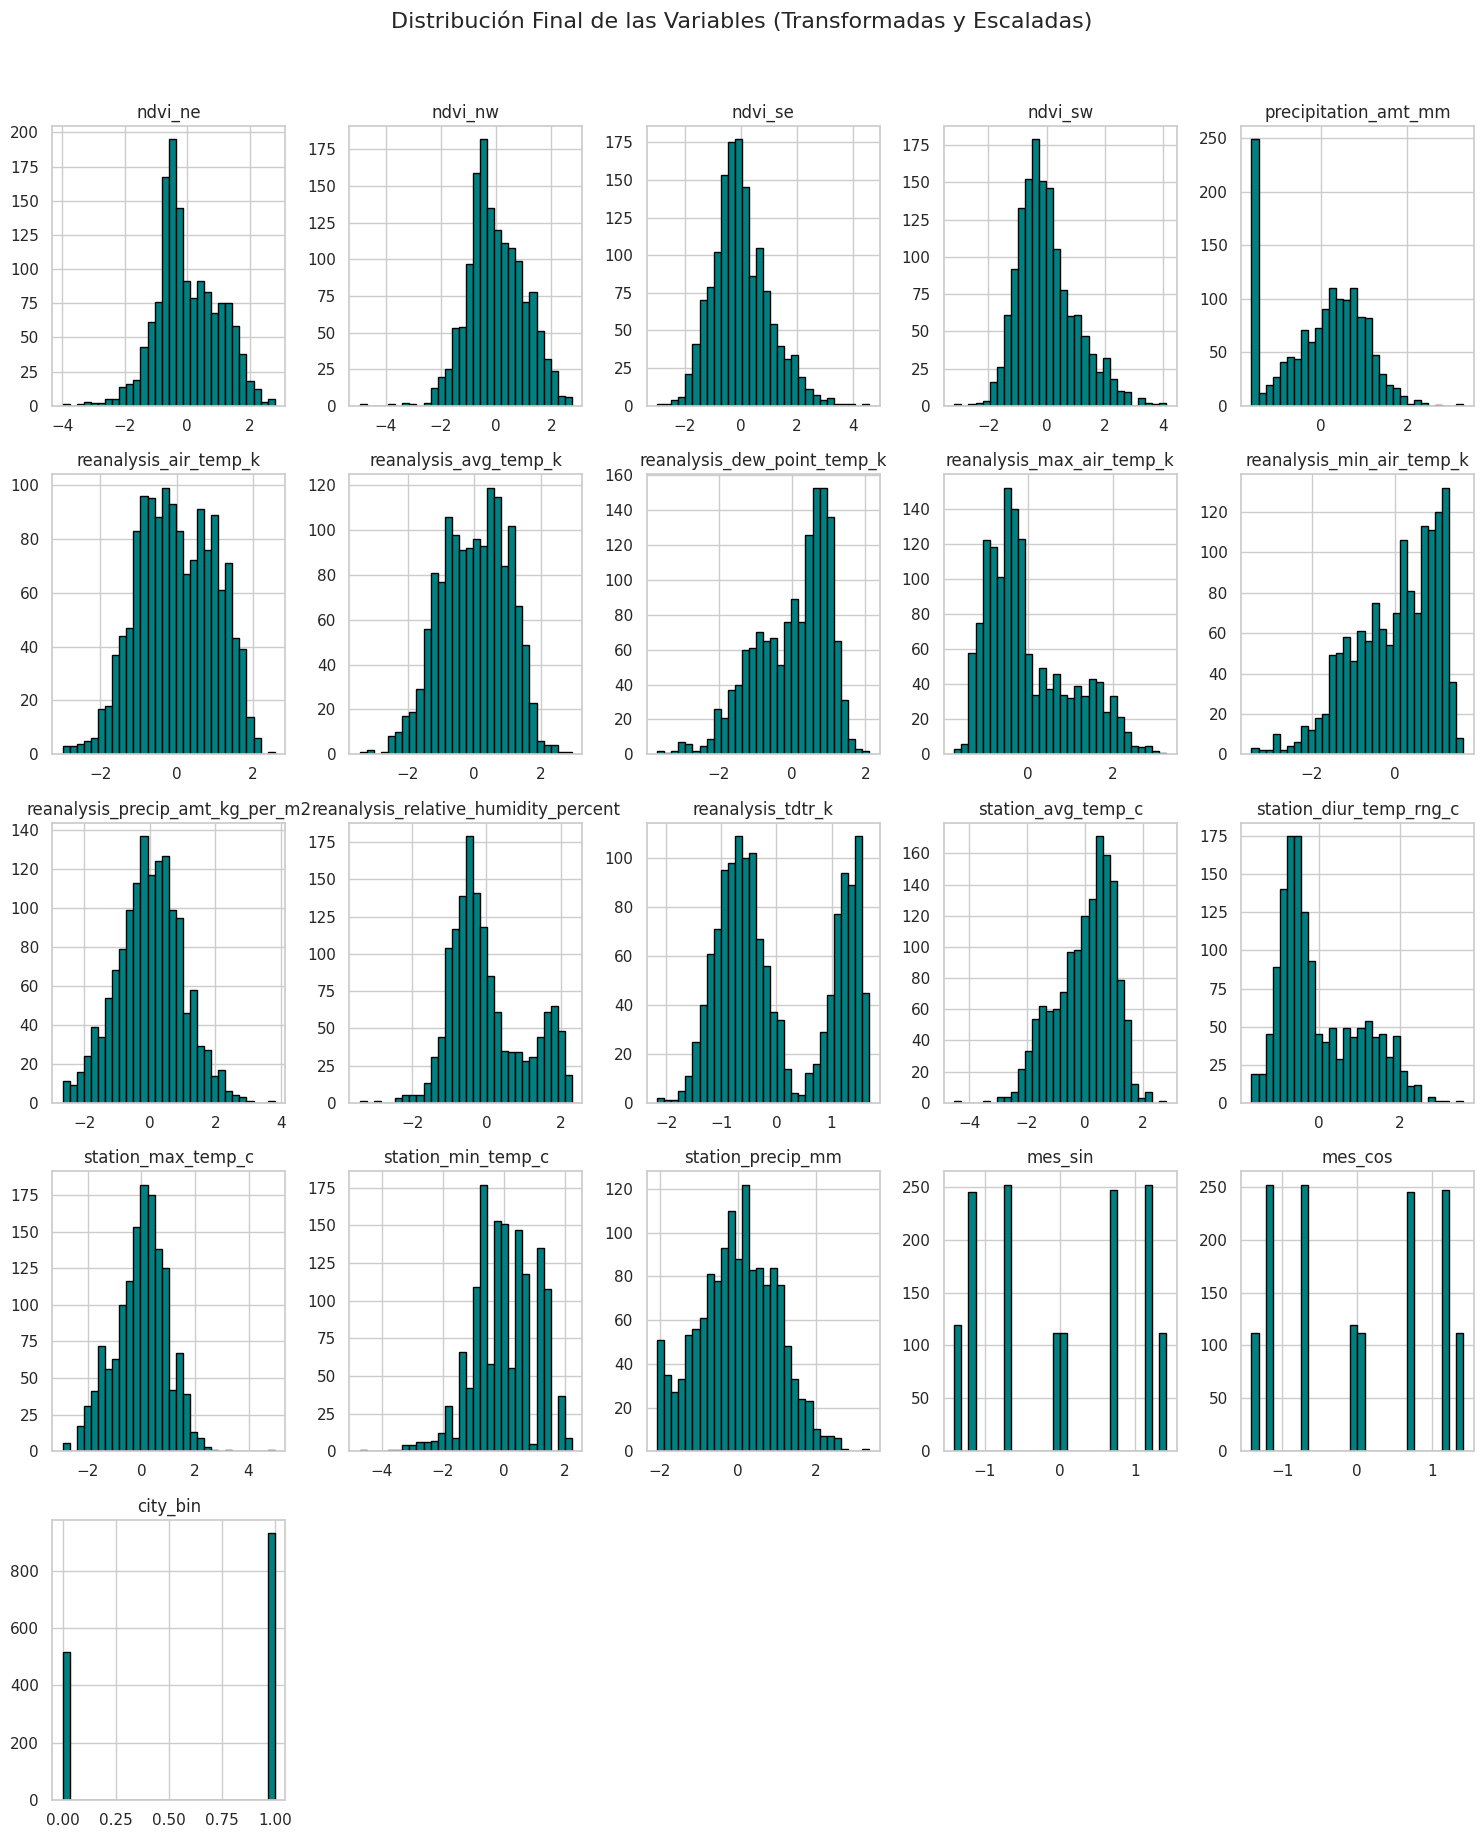

In [18]:
# Verificación de la distribución de los variables
train_scaled.hist(bins=30, figsize=(15, 18), color='teal', edgecolor='black')

plt.suptitle("Distribución Final de las Variables (Transformadas y Escaladas)", y=1.02, fontsize=16)
plt.tight_layout()
plt.show()

### Verificación Características

Con esta cuadrícula de gráficos podemos confirmar que las transformaciones y la normalización fue exitosa, sí bien algunas variables aún no tienen una distribución normal, no tienen asimetrias tan marcadas. Además es importante mencionar que sí bien las precipitaciones fueron transformadas, siguen habiendo valores de cero, lo que es lo que queríamos, ya que el cero representa la realidad natural de que la mayoría de días del año no llueve.

Finalmente podemos ver como la escala de todas las variables en este punto es muy similar, ya que las variables están ahora centradas en 0 y su mayoría oscila entre -3 y 3.

## Análisis del Dataset Traspuesto
Para evaluar la similitud y cercanía estructural entre las características, trasponemos la matriz de datos estandarizada previamente para que las variables actúen como observaciones. Además realizamos un proceso de reducción de la dimensionalidad a 2 dimensiones mediante PCA para facilitar la visualización. Esto nos permite identificar visualmente familias de características que comparten comportamientos idénticos o fuertemente alineados

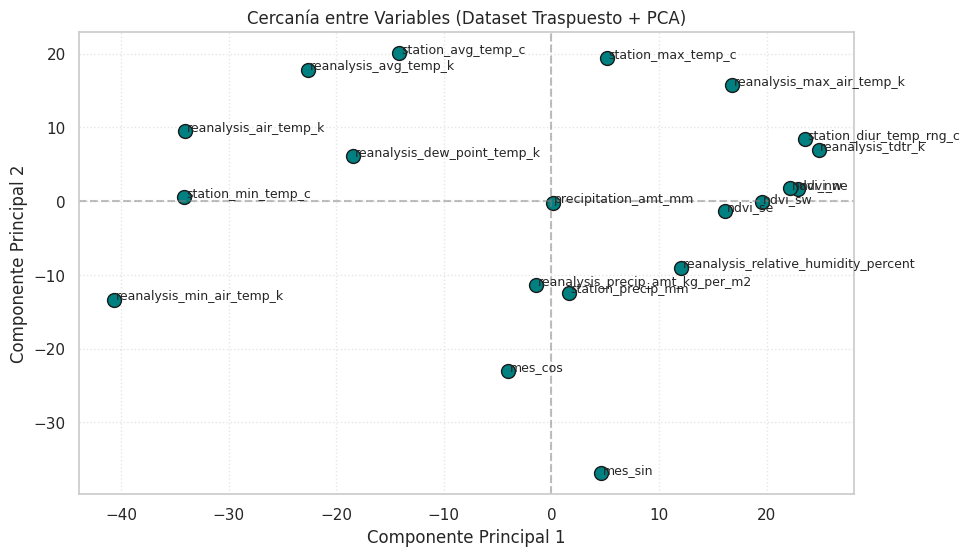

In [19]:
# Proyección 2D del dataset traspuesto
cols_model = [c for c in train_scaled.columns if c != 'city_bin']
coords = PCA(n_components=2, random_state=seed).fit_transform(
    train_scaled[cols_model].T
)

# Gráfico en el plano cartesiano
plt.figure(figsize=(10, 6))
plt.scatter(coords[:, 0], coords[:, 1], color='teal', edgecolor='k', s=100)

for i, var in enumerate(cols_model):
  plt.annotate(var, (coords[i, 0] + 0.15, coords[i, 1]), fontsize=9)

plt.axhline(0, color='grey', linestyle='--', alpha=0.5)
plt.axvline(0, color='grey', linestyle='--', alpha=0.5)
plt.title('Cercanía entre Variables (Dataset Traspuesto + PCA)')
plt.xlabel('Componente Principal 1')
plt.ylabel('Componente Principal 2')
plt.grid(True, linestyle=':', alpha=0.5)
plt.show()

**Análisis del dataset traspuesto**

Al análizar el dataset traspuesto en dos dimensiones por medio de PCA, podemos observar como se forman diferentes clusters.

- En el extremo izquierdo, reanalysis_min_air_temp_k y station_min_temp_c están prácticamente pegadas. Esto demuestra una gran coincidencia entre lo que registra la estación en tierra y lo que calcula el modelo de reanálisis satelital para las noches o momentos más fríos.

- En la zona derecha, las mediciones del noreste (ndvi_ne) y noroeste (ndvi_nw) se encuentran casi superpuestas, mostrando un comportamiento idéntico en la cobertura vegetal de la franja norte. De forma similar, las mediciones del sureste y suroeste (ndvi_se y ndvi_sw) forman su propio par muy cercano. Aunque en un proceso de simplificación severo se podría eliminar una variable de cada par por redundancia, decidimos conservarlas en este ejercicio para analizar cómo responde el algoritmo de clustering ante dimensiones fuertemente correlacionadas.

- Es interesante ver como en la parte derecha superior se agrupan las variables relacionadas con temperatura (mayoría) y en la misma zona pero inferior se agrupan las de precipitación y humedad, lo que tienen sentido al estar relacionadas naturalment. Sí bien estas están relacionadas, tienen una distancia aceptable visible entre ellas.

---
# Clustering
---

In [20]:
# PREPARACIÓN DE LA MATRIZ DE CLUSTERING (X_cluster)

# Seleccionamos todas las variables transformadas y escaladas
# Excluimos únicamente los identificadores temporales
cols_excluir = ['year', 'weekofyear', 'week_start_date', 'mes']
cols_cluster = [c for c in train_scaled.columns if c not in cols_excluir]

X_cluster = train_scaled[cols_cluster].copy()

print(
    f'Matriz X_cluster preparada con {X_cluster.shape[0]} instancias y {X_cluster.shape[1]} características.'
)
X_cluster.columns

Matriz X_cluster preparada con 1451 instancias y 21 características.


Index(['ndvi_ne', 'ndvi_nw', 'ndvi_se', 'ndvi_sw', 'precipitation_amt_mm',
       'reanalysis_air_temp_k', 'reanalysis_avg_temp_k',
       'reanalysis_dew_point_temp_k', 'reanalysis_max_air_temp_k',
       'reanalysis_min_air_temp_k', 'reanalysis_precip_amt_kg_per_m2',
       'reanalysis_relative_humidity_percent', 'reanalysis_tdtr_k',
       'station_avg_temp_c', 'station_diur_temp_rng_c', 'station_max_temp_c',
       'station_min_temp_c', 'station_precip_mm', 'mes_sin', 'mes_cos',
       'city_bin'],
      dtype='object')

## Algoritmo Jerárquico

Iniciamos con el algoritmo jerárquico aglomérativo, el cual clasifica las instancias por medio de un árbol.

In [21]:
# Correlación cofenética y evaluación de métodos de distancia

# Calculamos la matriz de distancias euclidianas entre todas las observaciones
dist_matrix = pdist(X_cluster, metric='euclidean')

# Evaluamos la Correlación Cofenética para cada método
metodos_linkage = ['ward', 'average', 'complete', 'single']
cofenetic_scores = {}

print("=== EVALUACIÓN DE CORRELACIÓN COFENÉTICA POR MÉTODO DE AGRUPACIÓN ===")
for method in metodos_linkage:
  Z = linkage(X_cluster, method=method)
  c, coph_dists = cophenet(Z, dist_matrix)
  cofenetic_scores[method] = c
  print(f"Método '{method}': {c:.4f}")

# Imprimimos los resultados
df_coph = pd.DataFrame(
    list(cofenetic_scores.items()), columns=['Método', 'Correlación_Cofenética']
)

=== EVALUACIÓN DE CORRELACIÓN COFENÉTICA POR MÉTODO DE AGRUPACIÓN ===
Método 'ward': 0.7193
Método 'average': 0.7685
Método 'complete': 0.7271
Método 'single': 0.6855


**Correlación cofenética**

Para medir qué método de distancia entre clústers mantiene la mayor fidelidad de la estructura de nuestros datos con la dimensionalidad de 21. Calculamos la correlación cofenética entre los 4 métodos. Es el más cercano a 1 que es el valor optimo, con un valor de 0.7685, razón por la cual tomaremos este método de distancia para la creación del dendograma.

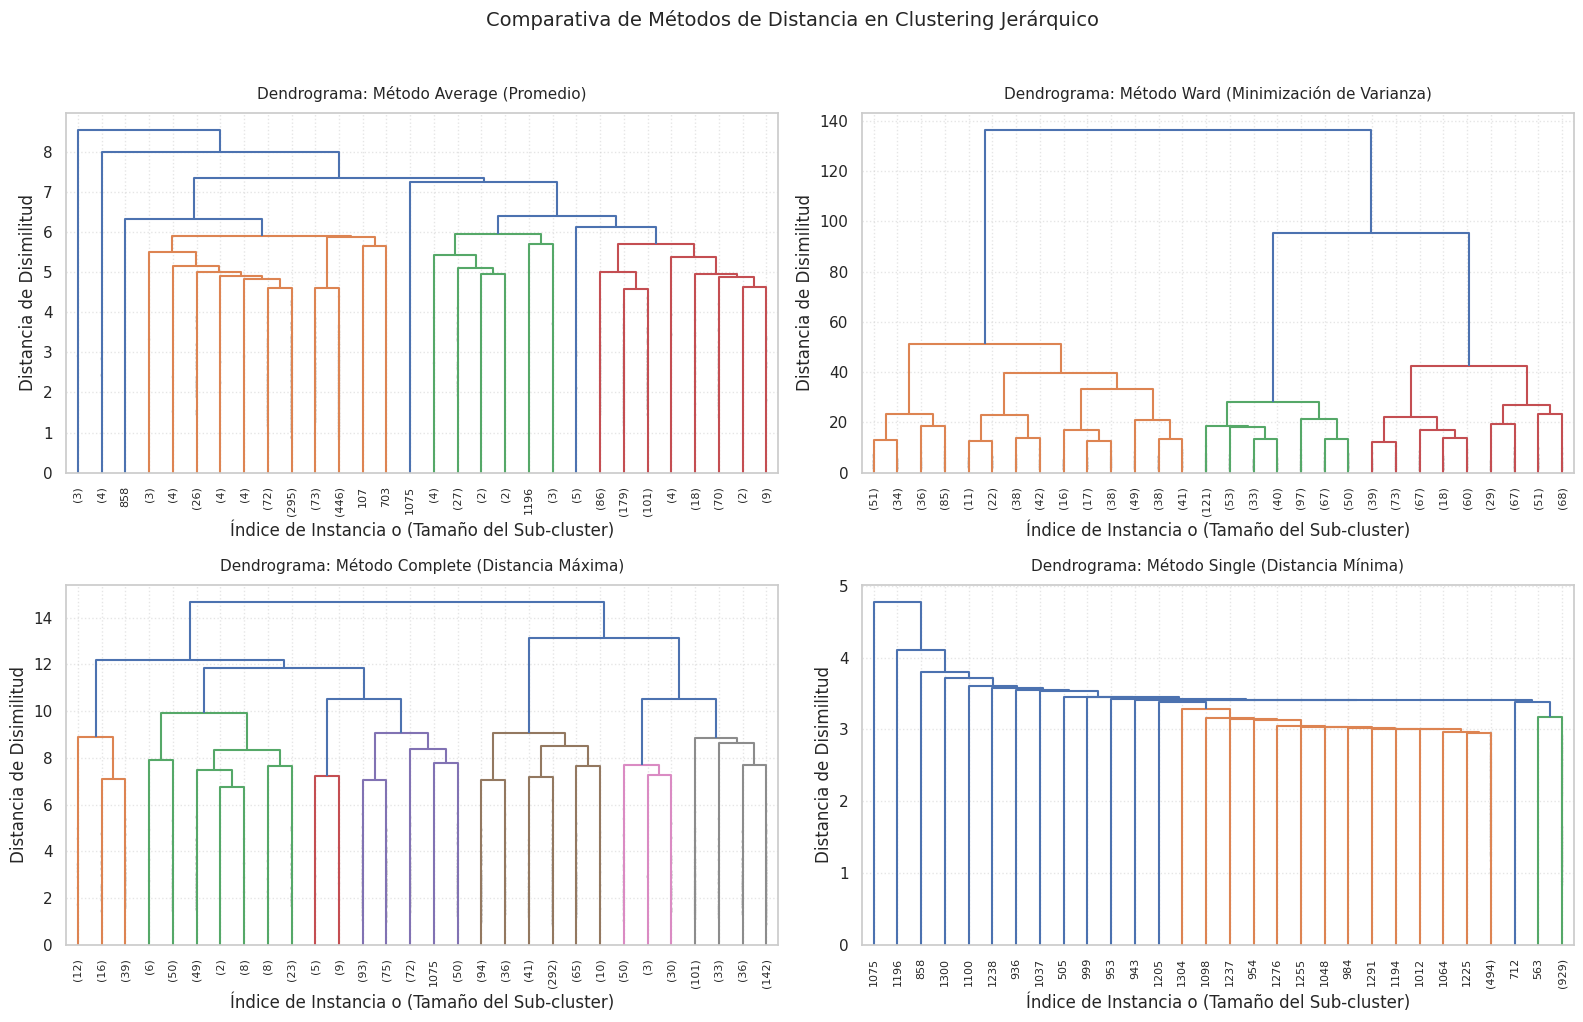

In [22]:
from scipy.cluster.hierarchy import dendrogram, linkage

# Lista de metodos de enlace a comparar
metodos = ['average', 'ward', 'complete', 'single']
titulos = [
    'Average (Promedio)',
    'Ward (Minimización de Varianza)',
    'Complete (Distancia Máxima)',
    'Single (Distancia Mínima)',
]

fig, axes = plt.subplots(2, 2, figsize=(16, 10))
axes = axes.flatten()

# Iteramos para generar cada dendrograma
for i, m in enumerate(metodos):
  # Calculamos la matriz de enlace especifica
  Z = linkage(X_cluster, method=m)

  # Graficamos el dendrograma en su respectivo sub-plot
  dendrogram(
      Z,
      truncate_mode='lastp',
      p=30,
      leaf_rotation=90.0,
      leaf_font_size=8.0,
      show_contracted=True,
      ax=axes[i],
  )

  axes[i].set_title(f'Dendrograma: Método {titulos[i]}', fontsize=11, pad=10)
  axes[i].set_xlabel('Índice de Instancia o (Tamaño del Sub-cluster)')
  axes[i].set_ylabel('Distancia de Disimilitud')
  axes[i].grid(True, linestyle=':', alpha=0.5)

plt.suptitle(
    'Comparativa de Métodos de Distancia en Clustering Jerárquico',
    fontsize=14,
    y=1.02,
)
plt.tight_layout()
plt.show()

**Dendogramas**

Sí bien en teoría el dendograma con el método de distancia average es el que teóricamente tiene la mejor fidelidad de la estructura de los datos. De manera visual pareciera que los métodos ward y complete tienen mejor resultados, estos funcionan mejor con dataset ruidosos, por lo que valdría la pena ver el resultado final con estos métodos también y compararlos con el mejor en la teoría.

Además es importante mencionar como tanto single como average logran capturar bastantes valores atípicos al inicio del dendograma, por lo que valdría la pena verificarlos y limpiarlos para mejorar el resultado en procesos futuros.

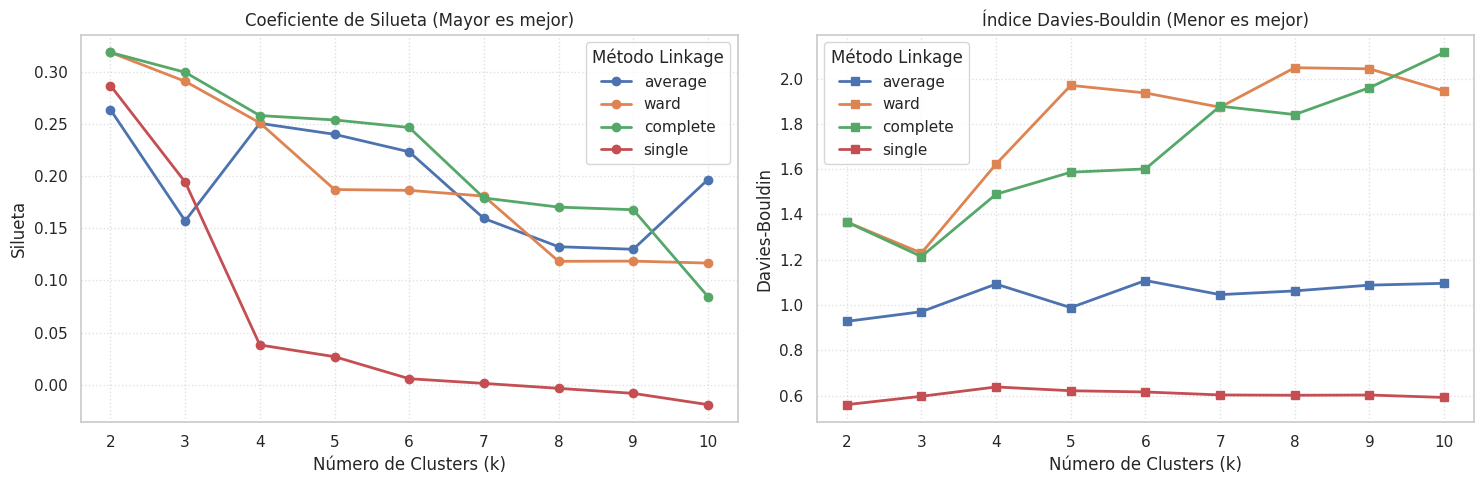

In [23]:
# Evaluación de calidad y determinación de K
metodos = ['average', 'ward', 'complete', 'single']
rango_k = range(2, 11)

# Almacenamiento de métricas por método
sil_scores = {m: [] for m in metodos}
db_scores = {m: [] for m in metodos}

# Cálculo en bucle simplificado
for m in metodos:
  for k in rango_k:
    labels = AgglomerativeClustering(n_clusters=k, linkage=m).fit_predict(
        X_cluster
    )
    sil_scores[m].append(silhouette_score(X_cluster, labels))
    db_scores[m].append(davies_bouldin_score(X_cluster, labels))

# Visualización comparativa de los 4 métodos
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))

for m in metodos:
  ax1.plot(rango_k, sil_scores[m], marker='o', linewidth=2, label=m)
  ax2.plot(rango_k, db_scores[m], marker='s', linewidth=2, label=m)

ax1.set_title('Coeficiente de Silueta (Mayor es mejor)')
ax1.set_xlabel('Número de Clusters (k)')
ax1.set_ylabel('Silueta')
ax1.grid(True, linestyle=':', alpha=0.6)
ax1.legend(title='Método Linkage')

ax2.set_title('Índice Davies-Bouldin (Menor es mejor)')
ax2.set_xlabel('Número de Clusters (k)')
ax2.set_ylabel('Davies-Bouldin')
ax2.grid(True, linestyle=':', alpha=0.6)
ax2.legend(title='Método Linkage')

plt.tight_layout()
plt.show()

**Validación de calidad**
- Coeficiente de Silueta: Los métodos dew distancia Ward y Complete alcanzan sus mejores valores en k=2 y 3. Single y Average no alcanzan a tener el mismo rendimiento, sin embargo average se recupera un poco en K=4. Esto es importante porque este coeficiente nos indica que tan separados están los clústers entre sí y que tanta cohesión tienen entre sí. Nuevamente vemos cómo Ward y Complete pareciera que tienen mejores resultados.

- Índice de Davies-Bouldin: Este funciona en vía contraria al de Silueta, ya que calcula la peor relación entre cohesión y separación, por lo que valores menores son mejores, en este vemos mejores resultados en average y single y podemos ver una tendencia hacia el K=3 como el valor óptimo de K.

En el coeficiente de Silueta vemos un valor óptimo de K=2 para todos y en el Índice de Davies-Bouldin K=3 con un contraste más claro, por lo que usaremos 2 y 3 para ver cuál tiene mejor resultados.

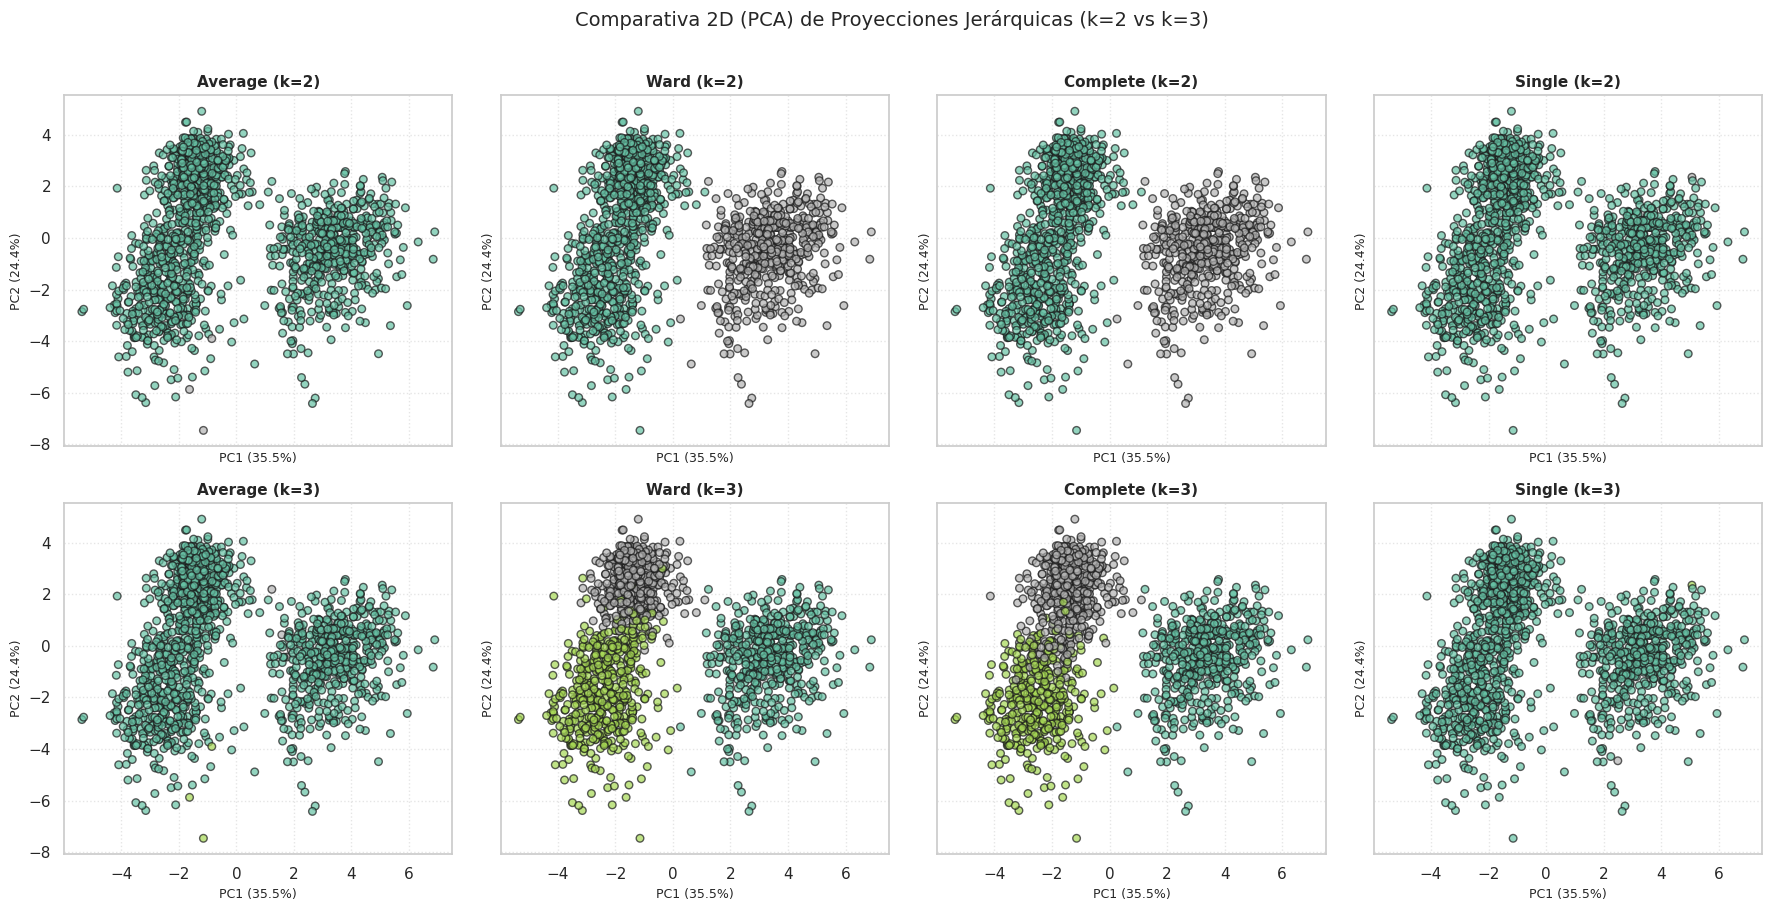

In [24]:
# Imprimir clusterización en 2D
metodos = ['average', 'ward', 'complete', 'single']
valores_k = [2, 3]

# Proyección PCA a 2D
pca_vis = PCA(n_components=2, random_state=seed)
X_vis_2d = pca_vis.fit_transform(X_cluster)

# Generación de matriz de gráficos 2x4 (Filas: k=2 y k=3, Columnas: Métodos)
fig, axes = plt.subplots(
    len(valores_k), len(metodos), figsize=(18, 9), sharex=True, sharey=True
)

for row_idx, k in enumerate(valores_k):
  for col_idx, m in enumerate(metodos):
    labels = AgglomerativeClustering(n_clusters=k, linkage=m).fit_predict(
        X_cluster
    )

    ax = axes[row_idx, col_idx]
    scatter = ax.scatter(
        X_vis_2d[:, 0],
        X_vis_2d[:, 1],
        c=labels,
        cmap='Set2',
        alpha=0.7,
        edgecolor='k',
        s=30,
    )
    ax.set_title(f'{m.capitalize()} (k={k})', fontsize=11, fontweight='bold')
    ax.set_xlabel(
        f'PC1 ({pca_vis.explained_variance_ratio_[0]*100:.1f}%)', fontsize=9
    )
    ax.set_ylabel(
        f'PC2 ({pca_vis.explained_variance_ratio_[1]*100:.1f}%)', fontsize=9
    )
    ax.grid(True, linestyle=':', alpha=0.5)

plt.suptitle(
    'Comparativa 2D (PCA) de Proyecciones Jerárquicas (k=2 vs k=3)',
    fontsize=14,
    y=1.01,
)
plt.tight_layout()
plt.show()

**Clusterización Jerárquica**

- Average y Single: Asignan casi la totalidad de datos a un solo cluster principal y utilizan los otros grupos únicamente para aislar outliers. Esto concuerda con los dendogramas en donde veíamos la asignación de clústers atípicos en K=2 y 3.

- Ward y Complete: Logran dividir la nube de datos en 3 regiones funcionales muy bien delimitadas, donde Ward logra ser superior de manera visual. Aquí logramos notar como logran generalizar también los valores atípicos, concordando con el uso de ellos en dataset ruidosos, En este proceso logra dividir posiblemente las dos ubicaciones geográficas y el caracter bimodal que presenta la ciudad de San juan que se veía en los datos de distribución inicial por ciudad. Mientras que el Clúster más estable correspondería a la ciudad de Iquitos.

## Algoritmo Particionante - K-Means

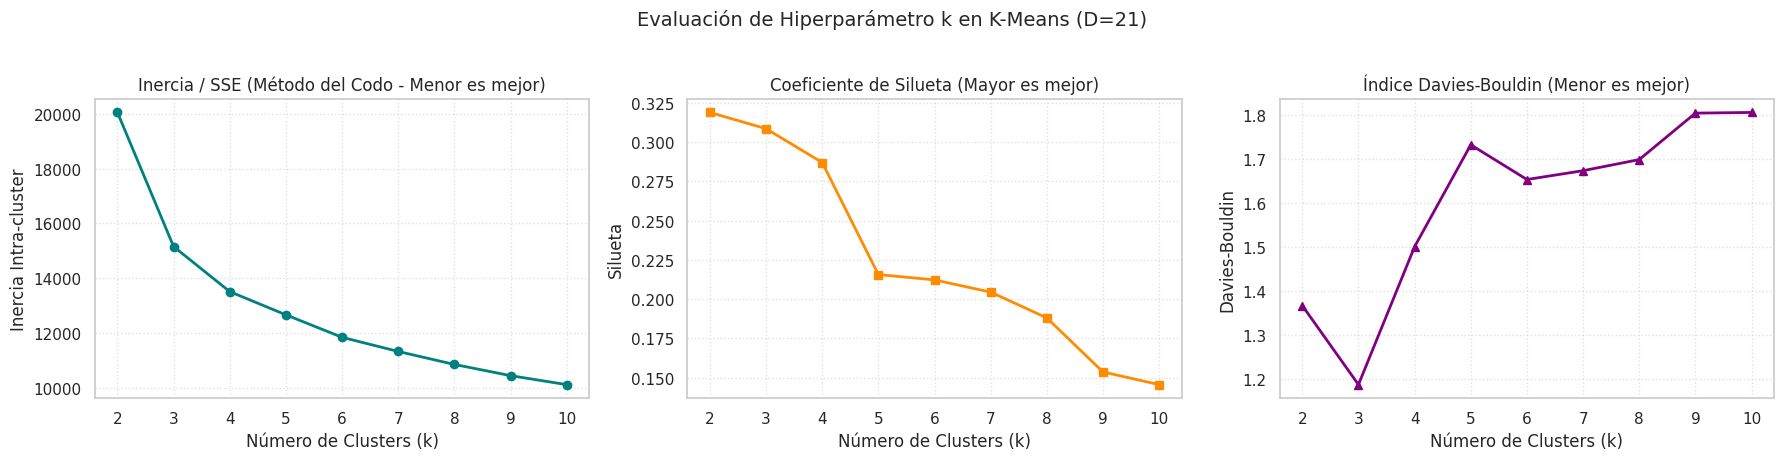

In [25]:
rango_k = range(2, 11)
inercias = []
siluetas_km = []
davies_km = []

for k in rango_k:
  # Usamos K-Means++ como método de inicialización eficiente
  km = KMeans(n_clusters=k, init='k-means++', n_init=10, random_state=seed)
  labels = km.fit_predict(X_cluster)

  inercias.append(km.inertia_)
  siluetas_km.append(silhouette_score(X_cluster, labels))
  davies_km.append(davies_bouldin_score(X_cluster, labels))

# Visualización en 3 métricas
fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(18, 4.5))

# Método del Codo (Inercia / SSE)
ax1.plot(rango_k, inercias, marker='o', color='teal', linewidth=2)
ax1.set_title('Inercia / SSE (Método del Codo - Menor es mejor)')
ax1.set_xlabel('Número de Clusters (k)')
ax1.set_ylabel('Inercia Intra-cluster')
ax1.grid(True, linestyle=':', alpha=0.6)

# Coeficiente de Silueta
ax2.plot(rango_k, siluetas_km, marker='s', color='darkorange', linewidth=2)
ax2.set_title('Coeficiente de Silueta (Mayor es mejor)')
ax2.set_xlabel('Número de Clusters (k)')
ax2.set_ylabel('Silueta')
ax2.grid(True, linestyle=':', alpha=0.6)

# Índice de Davies-Bouldin
ax3.plot(rango_k, davies_km, marker='^', color='purple', linewidth=2)
ax3.set_title('Índice Davies-Bouldin (Menor es mejor)')
ax3.set_xlabel('Número de Clusters (k)')
ax3.set_ylabel('Davies-Bouldin')
ax3.grid(True, linestyle=':', alpha=0.6)

plt.suptitle(
    'Evaluación de Hiperparámetro k en K-Means (D=21)', fontsize=14, y=1.02
)
plt.tight_layout()
plt.show()

**Evaluación hiperparámetros K-means**

- Inercia / SSE (Método del Codo): Muestra el cambio de pendiente más pronunciado al pasar de k=2 a 3, luego del 3 los cambios son más suaves.

- Coeficiente de Silueta (Mayor es mejor): Mantiene sus niveles más altos y estables en k=2 y 3. A partir de k=4, la calidad de la separación parece ser muy mala.  

- Índice Davies-Bouldin (Menor es mejor): Alcanza su mínimo en k=3, confirmando que esta configuración logra la mejor relación entre cohesión y separación interclúster.   

Conclusión: Las tres métricas coinciden en que k=2 y 3 son las óptimas.

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but PCA was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but PCA was fitted with feature names
  warnings.warn(


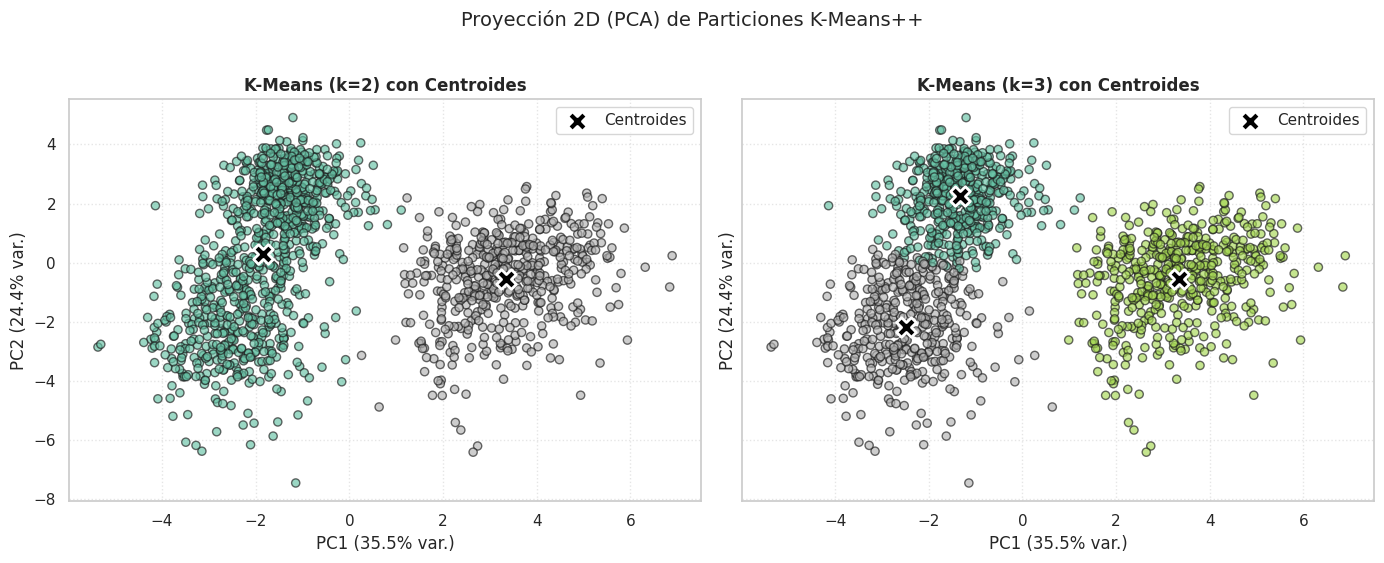

In [26]:
# Representación de K-means en 2D
valores_k = [2, 3]

# Proyección PCA a 2D para visualización
pca_vis = PCA(n_components=2, random_state=seed)
X_vis_2d = pca_vis.fit_transform(X_cluster)

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5), sharex=True, sharey=True)

for i, k in enumerate(valores_k):
  km = KMeans(n_clusters=k, init='k-means++', n_init=10, random_state=seed)
  labels = km.fit_predict(X_cluster)
  centroides_2d = pca_vis.transform(km.cluster_centers_)

  # Graficamos las observaciones
  scatter = axes[i].scatter(
      X_vis_2d[:, 0],
      X_vis_2d[:, 1],
      c=labels,
      cmap='Set2',
      alpha=0.65,
      edgecolor='k',
      s=35,
  )

  # Marcamos los centroides geométricos con una 'X'
  axes[i].scatter(
      centroides_2d[:, 0],
      centroides_2d[:, 1],
      c='black',
      marker='X',
      s=200,
      linewidths=2,
      edgecolors='white',
      label='Centroides',
  )

  axes[i].set_title(
      f'K-Means (k={k}) con Centroides', fontsize=12, fontweight='bold'
  )
  axes[i].set_xlabel(
      f'PC1 ({pca_vis.explained_variance_ratio_[0]*100:.1f}% var.)'
  )
  axes[i].set_ylabel(
      f'PC2 ({pca_vis.explained_variance_ratio_[1]*100:.1f}% var.)'
  )
  axes[i].legend()
  axes[i].grid(True, linestyle=':', alpha=0.5)

plt.suptitle(
    'Proyección 2D (PCA) de Particiones K-Means++', fontsize=14, y=1.02
)
plt.tight_layout()
plt.show()

**Proyección 2D de K-Means con PCA**

- K-Means (k=2): Separa de manera similar al anterior algoritmo la masa de datos en dos grandes bloques reflejando la diferencia geográfica base entre San Juan e Iquitos.   

- K-Means (k=3): Mantiene intacto el grupo de la derecha y sub-divide funcionalmente la masa de la izquierda en dos grupos capturando las variaciones de régimen climático de San juan que previamente identificamos.

K-Means al trabajar bien con datos en forma globular logra distinguir muy bien las dos ciudades y también la variabilidad interna de San juan.

## Algoritmos basado en densidad - DBSCAN

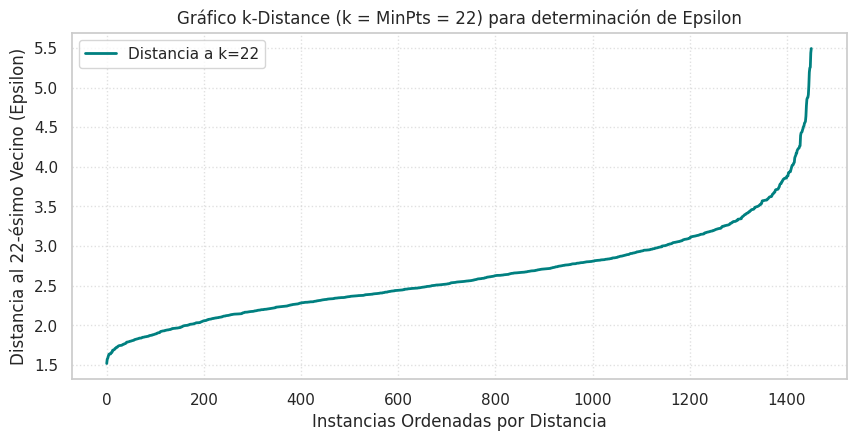

In [27]:
# Fijamos MinPts según la regla empírica MinPts >= D + 1 (D=21)
min_pts = 22

# Calculamos las distancias al k-ésimo vecino más cercano (k = min_pts)
nn = NearestNeighbors(n_neighbors=min_pts)
nn.fit(X_cluster)
distances, _ = nn.kneighbors(X_cluster)

# Tomamos la distancia al vecino k-ésimo y las ordenamos
k_distances = np.sort(distances[:, -1])

# Gráfico k-Distance (Método del Codo para Epsilon)
plt.figure(figsize=(10, 4.5))
plt.plot(k_distances, color='teal', linewidth=2, label=f'Distancia a k={min_pts}')
plt.title(
    f'Gráfico k-Distance (k = MinPts = {min_pts}) para determinación de Epsilon'
)
plt.xlabel('Instancias Ordenadas por Distancia')
plt.ylabel(f'Distancia al {min_pts}-ésimo Vecino (Epsilon)')
plt.legend()
plt.grid(True, linestyle=':', alpha=0.6)
plt.show()

**Determinación valor de Epsilon**

Gráfico k-Distance: La curva se mantiene relativamente plana y estable en distancias bajas, pero comienza a inclinarse fuertemente a partir de la instancia 1,000.

El "codo" de la gráfica se ubica alrededor de 2.8 que es cuando comienza a subir, indicando el umbral donde los datos normales encuentran sus 22 vecinos y las observaciones atípicas empiezan a disparar su distancia.   

In [28]:
#Evaluación de DBScan

eps_valores = [2.0, 2.5, 2.8, 3.0, 3.5]
resultados_db = []

for eps in eps_valores:
  db = DBSCAN(eps=eps, min_samples=min_pts)
  labels = db.fit_predict(X_cluster)

  # Filtramos los puntos ruido (-1) para las métricas internas
  mask_no_noise = labels != -1
  n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
  n_ruido = list(labels).count(-1)
  pct_ruido = (n_ruido / len(labels)) * 100

  # Calculamos métricas solo si existen al menos 2 clusters sin contar el ruido
  if n_clusters > 1 and mask_no_noise.sum() > 0:
    sil = silhouette_score(X_cluster[mask_no_noise], labels[mask_no_noise])
    db_score = davies_bouldin_score(
        X_cluster[mask_no_noise], labels[mask_no_noise]
    )
  else:
    sil, db_score = np.nan, np.nan

  resultados_db.append({
      'Eps': eps,
      'MinPts': min_pts,
      'Clusters_Creados': n_clusters,
      'Puntos_Ruido': n_ruido,
      '%_Ruido': f'{pct_ruido:.1f}%',
      'Silueta_Sin_Ruido': round(sil, 4) if not np.isnan(sil) else 'N/A',
      'Davies_Bouldin_Sin_Ruido': (
          round(db_score, 4) if not np.isnan(db_score) else 'N/A'
      ),
  })

df_dbscan_eval = pd.DataFrame(resultados_db)
print("=== EVALUACIÓN DE HIPERPARÁMETROS PARA DBSCAN ===")
display(df_dbscan_eval)

=== EVALUACIÓN DE HIPERPARÁMETROS PARA DBSCAN ===


,Eps,MinPts,Clusters_Creados,Puntos_Ruido,%_Ruido,Silueta_Sin_Ruido,Davies_Bouldin_Sin_Ruido
0,2.0,22,2,972,67.0%,0.5031,0.7592
1,2.5,22,3,299,20.6%,0.2797,1.2669
2,2.8,22,2,103,7.1%,0.3305,1.2845
3,3.0,22,2,53,3.7%,0.3259,1.3152
4,3.5,22,1,19,1.3%,N/A,N/A


**Evaluación de Hiperparámetros**

- Epsilon: Un valor bajo de Epsilon no logrará agrupar la cantidad esperada de instancias, ya que al no alcanzar va a comenzar a umentar el número de datos clasificados como ruido. Lo que podemos observar con claridad al ver los resultados obtenidos con valores menores a 2.8 donde el ruido aumenta considerablemente. Mientras que 2.8 y 3 obtienen valores considerablemtne mejores. Ya sí aumentamos a 3.5 vemos como al ser tan grande epsilón generaliza todo en 1 solo clúster, ya que siempre cumplirá la condición de los 22 puntos mínimos.

En este punto los candidatos serían 2.8 y 3, los cuales vamos a evaluyar de manera visual, para tomar una decisión.

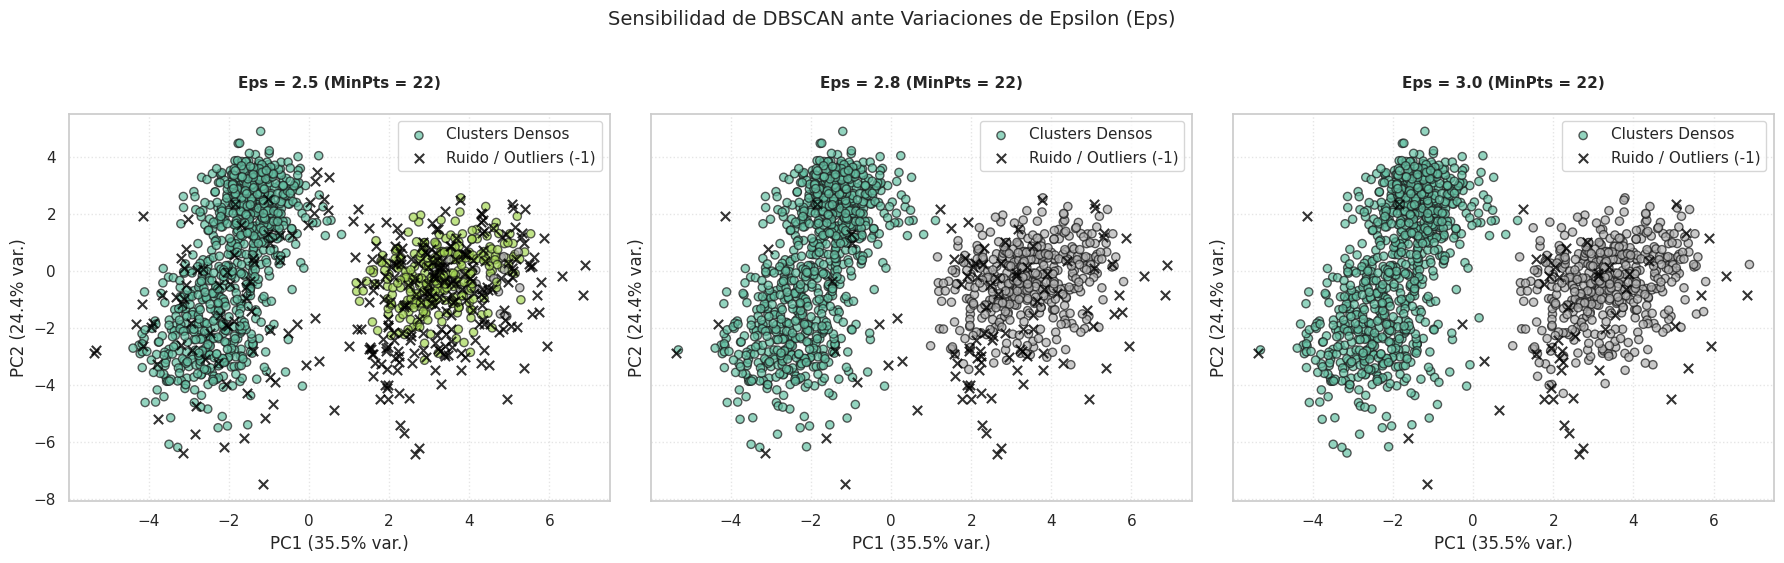

In [29]:
# Graficar y comparar resultados de DBScan

# Definición de valores de Epsilon a comparar
eps_valores = [2.5, 2.8, 3.0]

# Proyección PCA 2D para la visualización
pca_vis = PCA(n_components=2, random_state=seed)
X_vis_2d = pca_vis.fit_transform(X_cluster)

# Configuración del lienzo con 3 subplots horizontales
fig, axes = plt.subplots(1, 3, figsize=(18, 5.5), sharex=True, sharey=True)

estadisticas_dbscan = []

for i, eps in enumerate(eps_valores):
  # Ajustamos DBSCAN temporalmente para el epsilon actual
  db = DBSCAN(eps=eps, min_samples=min_pts)
  labels = db.fit_predict(X_cluster)

  ax = axes[i]

  # Puntos pertenecientes a Clusters Reales (label >= 0)
  mask_cluster = labels != -1
  if mask_cluster.sum() > 0:
    ax.scatter(
        X_vis_2d[mask_cluster, 0],
        X_vis_2d[mask_cluster, 1],
        c=labels[mask_cluster],
        cmap='Set2',
        alpha=0.7,
        edgecolor='k',
        s=35,
        label='Clusters Densos',
    )

  # Puntos de Ruido / Outliers (label == -1)
  mask_ruido = labels == -1
  if mask_ruido.sum() > 0:
    ax.scatter(
        X_vis_2d[mask_ruido, 0],
        X_vis_2d[mask_ruido, 1],
        c='black',
        marker='x',
        s=45,
        alpha=0.8,
        label='Ruido / Outliers (-1)',
    )

  # Personalización del subplot
  ax.set_title(
      f'Eps = {eps} (MinPts = {min_pts})\n',
      fontsize=11,
      fontweight='bold',
  )
  ax.set_xlabel(f'PC1 ({pca_vis.explained_variance_ratio_[0]*100:.1f}% var.)')
  ax.set_ylabel(f'PC2 ({pca_vis.explained_variance_ratio_[1]*100:.1f}% var.)')
  ax.legend(loc='upper right')
  ax.grid(True, linestyle=':', alpha=0.5)

plt.suptitle(
    'Sensibilidad de DBSCAN ante Variaciones de Epsilon (Eps)',
    fontsize=14,
    y=1.02,
)
plt.tight_layout()
plt.show()

**Interpretación resultado proyección 2D**

Visualmente con epsilon 2.8 y 3 tenemos resultados muy similares, podemos observar como ambos pueden diferenciar muy bien los dos clusters que tenemos, lo que tiene sentido ya que dbscan clasifica muy bien grupos sin importar que no sean globulares,como el cluster de San Juan. Estos dos sí bien son parecidos, visualmente vemos como toma como atípicos muchos puntos que se encuentran en la mitad del clúster en Iquitos o el derecho, esto se puede deber a que hicimos una disminución de dimensionalidad y pueden ser atípicos en otras dimensiones. Sí bien con K=3 recuperaríamos aproximadamente 50 datos clasificados en un clúster y no como ruido. Vamos a mantener el resultado de 2.8 dado que tiene resultados parecidos, puede que esté capturando valores atípicos en otras dimensiones que no vemos a simple vista y esto se confirma con el Coeficiente de Silueta (donde valores más altos indican mejor separación) y el Índice de Davies-Bouldin (donde valores más bajos reflejan menor traslape).


## Clustering probabilístico Gaussianas (GMM - Gaussian Mixture Models)

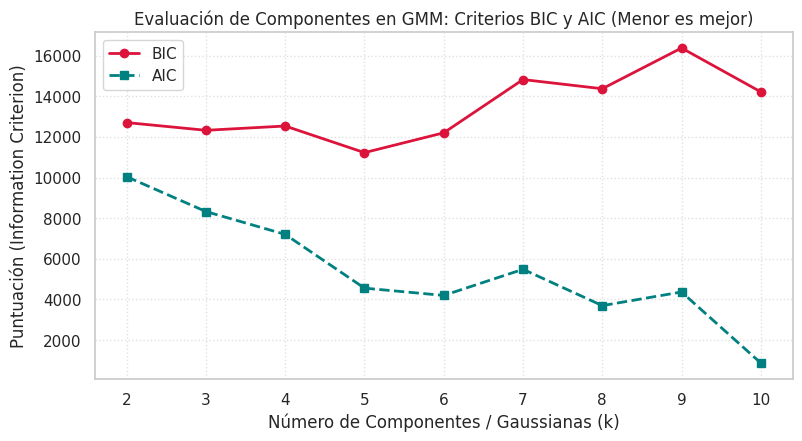

In [30]:
# Evaluación de componentes GMM - Gaussian Mixture Model
rango_k = range(2, 11)
bics = []
aics = []

for k in rango_k:
  # Usamos tipo de covarianza 'full' para permitir cualquier orientación y forma
  gmm = GaussianMixture(
      n_components=k,
      covariance_type='full',
      random_state=seed,
      n_init=5,
  )
  gmm.fit(X_cluster)
  bics.append(gmm.bic(X_cluster))
  aics.append(gmm.aic(X_cluster))

# Gráfico de evaluación BIC vs AIC
plt.figure(figsize=(9, 4.5))
plt.plot(
    rango_k, bics, marker='o', color='crimson', linewidth=2, label='BIC'
)
plt.plot(
    rango_k,
    aics,
    marker='s',
    color='teal',
    linestyle='--',
    linewidth=2,
    label='AIC',
)

plt.title(
    'Evaluación de Componentes en GMM: Criterios BIC y AIC (Menor es mejor)'
)
plt.xlabel('Número de Componentes / Gaussianas (k)')
plt.ylabel('Puntuación (Information Criterion)')
plt.legend()
plt.grid(True, linestyle=':', alpha=0.6)
plt.show()

**Evaluación de Componentes (Criterios BIC Bayesian Information Criterion y AIC Akaike Information Criterion)**

Criterio BIC: Muestra una caída inicial clara hacia k=3 y alcanza un mínimo en k=5, punto a partir del cual el indicador sube drásticamente penalizando el posible sobreajuste.   

Criterio AIC: Mantiene una tendencia decreciente constante al ser menos riguroso con la complejidad del modelo.   

Selección Óptima: K=5 gaussianas parece ser el mejor según esta validación de calidad, sin embargo el 3 tiene resultados buenos también por lo que lo probaremos también para poder evaluar los resultados de ambos.

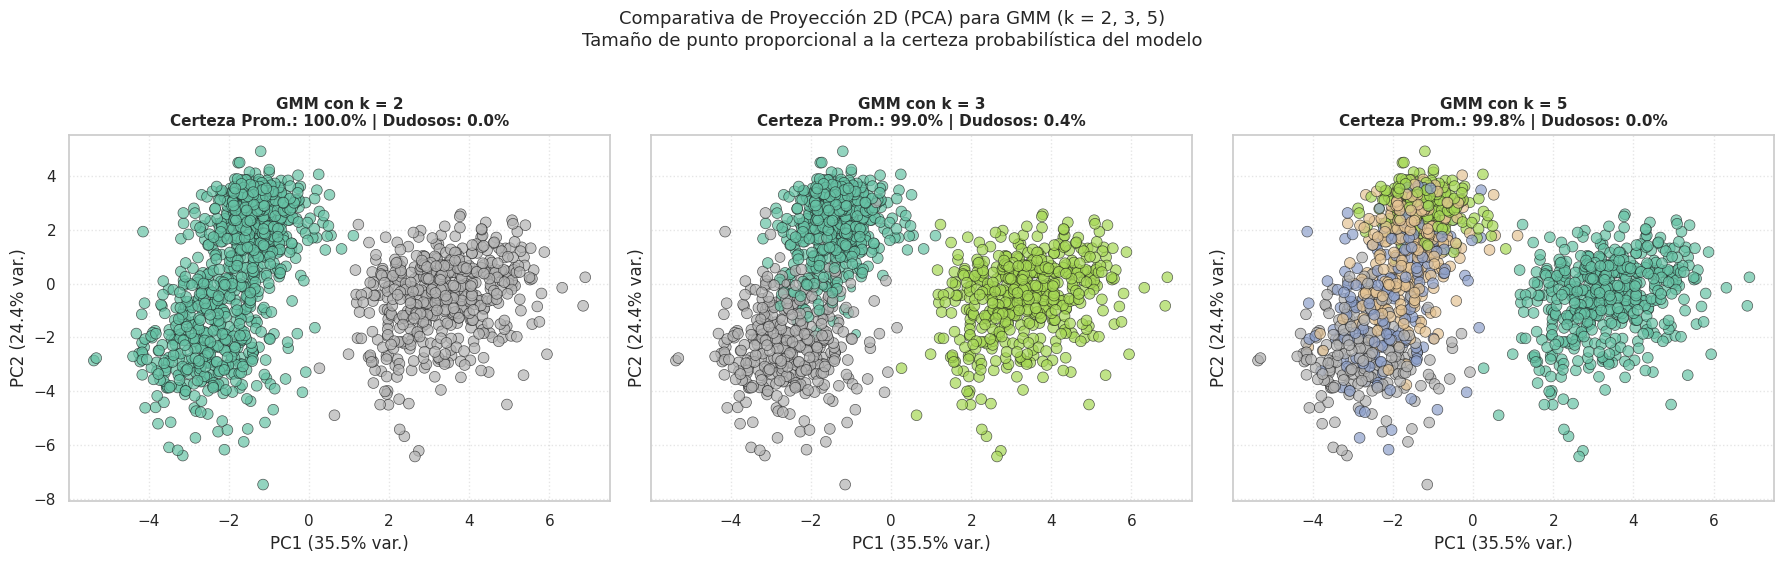

=== RESUMEN COMPARATIVO DE CERTEZA PROBABILÍSTICA (GMM) ===


,Componentes (k),Certeza Promedio,Puntos Dudosos (<60%),% Puntos Dudosos,BIC (Menor es mejor),AIC (Menor es mejor)
0,2,100.0%,0,0.0%,12705.4,10039.0
1,3,99.0%,6,0.4%,12325.0,8322.8
2,5,99.8%,0,0.0%,11224.9,4550.9


In [31]:
# Mostrar los resultados en 2D

# Definición de componentes/clústeres (k) a comparar
k_valores = [2, 3, 5]

# Proyección PCA 2D para visualización
pca_vis = PCA(n_components=2, random_state=seed)
X_vis_2d = pca_vis.fit_transform(X_cluster)

# Configuración del lienzo con 3 subplots horizontales
fig, axes = plt.subplots(1, 3, figsize=(18, 5.5), sharex=True, sharey=True)

estadisticas_gmm = []

for i, k in enumerate(k_valores):
  # Ajuste temporal del modelo GMM para cada k
  gmm = GaussianMixture(
      n_components=k,
      covariance_type='full',
      random_state=seed,
      n_init=10,
  )
  labels = gmm.fit_predict(X_cluster)
  probs = gmm.predict_proba(X_cluster)
  max_prob = np.max(probs, axis=1)  # Certeza de asignación (de 0 a 1)

  ax = axes[i]

  # Dispersión 2D: El tamaño del punto es proporcional a la certeza probabilística
  scatter = ax.scatter(
      X_vis_2d[:, 0],
      X_vis_2d[:, 1],
      c=labels,
      cmap='Set2',
      alpha=0.7,
      s=max_prob * 60,
      edgecolor='k',
      linewidth=0.5,
  )

  # Cálculo de métricas de certidumbre probabilística
  certeza_media = np.mean(max_prob) * 100
  puntos_dudosos = np.sum(max_prob < 0.6)  # Observaciones con certeza < 60%
  pct_dudosos = (puntos_dudosos / len(X_cluster)) * 100

  estadisticas_gmm.append({
      'Componentes (k)': k,
      'Certeza Promedio': f'{certeza_media:.1f}%',
      'Puntos Dudosos (<60%)': puntos_dudosos,
      '% Puntos Dudosos': f'{pct_dudosos:.1f}%',
      'BIC (Menor es mejor)': round(gmm.bic(X_cluster), 1),
      'AIC (Menor es mejor)': round(gmm.aic(X_cluster), 1),
  })

  # Personalización del subplot
  ax.set_title(
      f'GMM con k = {k}\n'
      f'Certeza Prom.: {certeza_media:.1f}% | Dudosos: {pct_dudosos:.1f}%',
      fontsize=11,
      fontweight='bold',
  )
  ax.set_xlabel(f'PC1 ({pca_vis.explained_variance_ratio_[0]*100:.1f}% var.)')
  ax.set_ylabel(f'PC2 ({pca_vis.explained_variance_ratio_[1]*100:.1f}% var.)')
  ax.grid(True, linestyle=':', alpha=0.5)

plt.suptitle(
    'Comparativa de Proyección 2D (PCA) para GMM (k = 2, 3, 5)\n'
    'Tamaño de punto proporcional a la certeza probabilística del modelo',
    fontsize=13,
    y=1.02,
)
plt.tight_layout()
plt.show()

# Resumen comparativo de certidumbre e información (BIC / AIC)
df_stats_gmm = pd.DataFrame(estadisticas_gmm)
print("=== RESUMEN COMPARATIVO DE CERTEZA PROBABILÍSTICA (GMM) ===")
display(df_stats_gmm)

**Proyección 2D con PCA**

Las 3 gaussianas se adaptan con flexibilidad a la dispersión real de los datos, separando la región de la derecha (Iquitos) y dividiendo la masa de la izquierda (San Juan) en dos regímenes.   

Aunque el modelo con k=5 alcanza valores inferiores en los criterios BIC y AIC (11224.9 y 4550.9 respectivamente), se selecciona k=3, dado que de esta manera se pueden explicar mejor los régimenes ambientales. Aunque no se podría descartar la opción de tomar los 5 clusters y luego unirlos para que generar los 3 clústers.

In [32]:
# Generación de datos sintéticos
# Definimos el k óptimo y entrenamos el modelo GMM final
k_optimo = 3
gmm_final = GaussianMixture(
    n_components=k_optimo,
    covariance_type='full',
    random_state=seed,
    n_init=10,
)
gmm_final.fit(X_cluster)

# Muestreo de datos sintéticos
X_sint, y_sint = gmm_final.sample(n_samples=100)
idxs = [np.where(y_sint == k)[0][0] for k in range(k_optimo)]

# Des-escalar variables continuas
df_sintetico = pd.DataFrame(
    scaler.inverse_transform(X_sint[idxs, : len(cols_continuas)]),
    columns=cols_continuas,
)

# Asignar componente y mapear ciudad (0 = Iquitos, 1 = San Juan)
idx_city = list(X_cluster.columns).index('city_bin')
df_sintetico['Gaussiana_Generadora'] = range(k_optimo)

df_sintetico['Ciudad'] = [
    'San Juan (sj)' if val >= 0.5 else 'Iquitos (iq)'
    for val in X_sint[idxs, idx_city]
]

# Mostrar columnas relevantes
cols_relevantes = [
    'Gaussiana_Generadora',
    'Ciudad',
    'station_avg_temp_c',
    'station_max_temp_c',
    'station_min_temp_c',
    'station_diur_temp_rng_c',
    'precipitation_amt_mm',
    'reanalysis_relative_humidity_percent',
    'ndvi_ne',
    'ndvi_se',
]

print("=== MUESTRAS CLIMÁTICAS SINTÉTICAS ===")
display(df_sintetico[cols_relevantes])

=== MUESTRAS CLIMÁTICAS SINTÉTICAS ===


,Gaussiana_Generadora,Ciudad,station_avg_temp_c,station_max_temp_c,station_min_temp_c,station_diur_temp_rng_c,precipitation_amt_mm,reanalysis_relative_humidity_percent,ndvi_ne,ndvi_se
0,0,San Juan (sj),28.489677,34.423000,24.078740,7.995772,7.677086,77.751449,-0.027692,0.239255
1,1,Iquitos (iq),28.659800,35.905903,24.114582,9.631923,11.426912,88.747387,0.386121,0.377561
2,2,San Juan (sj),26.439742,32.072167,22.063807,7.353212,5.231644,83.028891,0.167547,0.159993


**Muestras Climáticas Sintéticas**

 Al aprender la distribución matemática continua del dataset, GMM no solo agrupa datos existentes, sino que nos permite usarlo como un motor generativo. En estos datos generados nos damos cuenta que la diferencia entre San Juan tiene que ver con la temperatura y la precipitación y dado que las variables climáticas están relacionadas o conectadas logramos con este régimen bimodal identificar las diferencias existentes entre los 2 clústers de esta ciudad. Muentras que Iquitos presenta condiciones más estables en comparación con San juan, por eso solo tenemos un gran clúster que representa sus condiciones en terminos generales.

---
# Conclusiones
---

## Comparación de algoritmos
En esta sección vamos a comparar en terminos generales el resultado de cada algoritmo de cluster

In [33]:
# Comparación entre modelos

# Definición de los 4 modelos finales óptimos seleccionados
modelos = {
    'Jerárquico (Ward, k=3)': AgglomerativeClustering(
        n_clusters=3, linkage='ward'
    ),
    'K-Means++ (k=3)': KMeans(
        n_clusters=3, init='k-means++', n_init=10, random_state=seed
    ),
    'DBSCAN (eps=2.8)': DBSCAN(eps=2.8, min_samples=min_pts),
    'GMM Full (k=3)': GaussianMixture(
        n_components=3,
        covariance_type='full',
        random_state=seed,
        n_init=10,
    ),
}

# Generación de etiquetas y matriz comparativa de métricas
resumen_metricas = []

for nombre, modelo in modelos.items():
  # Asignación de clústeres
  labels = modelo.fit_predict(X_cluster)

  # Guardado automático de la columna en train
  col_name = f"cluster_{nombre.split()[0].lower()}"
  train[col_name] = labels

  # Si es GMM, se adjunta la certidumbre probabilística máxima
  if 'GMM' in nombre:
    train['prob_max_gmm'] = np.max(modelo.predict_proba(X_cluster), axis=1)

  # Filtrado de ruido (-1) para el cálculo justo de métricas en DBSCAN
  mask = labels != -1
  n_clusters = len(np.unique(labels[mask]))
  pct_ruido = (np.sum(~mask) / len(labels)) * 100

  # Métricas de calidad geométrica sobre datos sin ruido
  sil = (
      silhouette_score(X_cluster[mask], labels[mask])
      if n_clusters > 1
      else np.nan
  )
  db = (
      davies_bouldin_score(X_cluster[mask], labels[mask])
      if n_clusters > 1
      else np.nan
  )

  resumen_metricas.append({
      'Algoritmo': nombre,
      'N° Clusters': n_clusters,
      '% Ruido': f'{pct_ruido:.1f}%',
      'Silueta': round(sil, 4),
      'Davies-Bouldin': round(db, 4),
  })

# Dataframe consolidado
df_matriz_comparativa = pd.DataFrame(resumen_metricas)

print("=== MATRIZ COMPARATIVA DE MÉTRICAS DE CALIDAD ===")
display(df_matriz_comparativa)

=== MATRIZ COMPARATIVA DE MÉTRICAS DE CALIDAD ===


,Algoritmo,N° Clusters,% Ruido,Silueta,Davies-Bouldin
0,"Jerárquico (Ward, k=3)",3,0.0%,0.2910,1.2299
1,K-Means++ (k=3),3,0.0%,0.3085,1.1873
2,DBSCAN (eps=2.8),2,7.1%,0.3305,1.2845
3,GMM Full (k=3),3,0.0%,0.2970,1.2322


**Análisis entre los mejores modelos**

El dataset responde a dos geografías opuestas: Iquitos (selva amazónica continental) y San Juan (costa caribeña). Mientras Iquitos mantiene un perfil de bosque forestal amazónico y húmedo estable todo el año con pequeñas variaciones, San Juan presenta una marcada bimodalidad climática dividida entre época seca y época de lluvias/transición que se evidencia por medio de su forma alargada que se clasifica en 2 clústeres.

- K-Means++ ($k=3$):Obtiene el mejor desempeño clasificando el 100% de las semanas (Silueta 0.3085, Davies-Bouldin 1.1873). Separa con precisión la masa de Iquitos de las dos estaciones meteorológicas de San Juan (seca y lluviosa), siendo la mejor opción para segmentar todo el histórico de datos.

- GMM Full ($k=3$):Logra métricas muy buenas (Silueta 0.2970, DB 1.2322) Además al ser probabilístico, modela suavemente la transición entre la época seca y húmeda de San Juan, permitiendo medir la incertidumbre en semanas atípicas y generar muestras climáticas sintéticas para ejercicios posteriores o para verificar las diferencias entre los clústers.

- Jerárquico Ward ($k=3$):Confirma la estructura de los datos mediante la minimización de varianza. Valida de forma independiente que los 3 regímenes ambientales emergen naturalmente sin forzar la geometría de los grupos.Aunque es importante mencionar que este nos funcionó por tener un dataset ruidoso, por lo que sería útil usarlo para limpiar los datos enfocándonos en los atípicos que logró identificar.


DBSCAN ($epsilon=2.8$):Registra la mayor silueta (0.3305) únicamente porque aísla un 7.1% de la muestra como ruido, causado por valores atípicos. Al depender exclusivamente de la densidad espacial, agrupa a San Juan en un solo bloque y genera solo 2 clústeres, por lo que no sirve para clasificar estaciones dentro de una misma ubicación geográfica, sino como filtro de eventos climáticos atípicos.

## Variables finales y transformaciones

La eliminación de variables altamente redundantes (reanalysis_sat_precip_amt_mm y reanalysis_specific_humidity_g_per_kg) fue fundamental para evitar la sobre-ponderación de distancias en las dimensiones relacionadas con humedad y lluvia. Asimismo, la imputación por mediana agrupada nos ayudó a preservar la estacionalidad local de cada ciudad, mientras que la eliminación de la semana 53 evitó introducir ruido artificial en los cálculos de distancia, esto último fue crucial, porque aunque las variables climáticas pueden ser muy similares de un día para otra, toda una semana con valores nulos solo introduciría ruido al dataset, inclusive sí lo llegaramos a imputar solo incrementaría el peso de la semana 52 sí por ejemplo ese hubiera sido nuestro parámetros de imputación.

la transformación de Yeo-Johnson fue clave para estabilizar la alta asimetría de las precipitaciones sin alterar el significado de las semanas sin lluvia (valores en cero). Por su parte, la codificación cíclica (mes_sin, mes_cos) permitió que los algoritmos reconocieran la continuidad estacional entre diciembre y enero, de otra manera hubiera tomado a diciembre como un mes muy distante a enero, que no corresponde a la realidad.

Finalmente la estandarización de todas las variables por medio de StandardScaler permitió que todas las variables fueran comparables entre ellas por los algoritmos de clusterización. Estos al basarse en distancias son muy sensibles a las magnitudes, por lo que este proceso permitio dar un peso de similar entre todas las variables reduciendo de esta manera posibles sesgos relacionados con distancias o magnitudes.



## Reutilización

**Qué reutilizar?**

- Preprocesamiento y limpieza: Las transformaciones aplicadas, la imputación de datos nulos, la binarización y la transformación ciclica de las fechas podrían llegar a ser muy útiles en procesos posteriores, ya que de esta manera se obtiene una vista minable con una calidad estable para procesos de machine learning.

- identificación de outliers con algorítmos de clúster: Tanto el algoritmo Jerárquico y DBScan nos permitieron identificar valores atípicos. Sería interesante realizar un análisis sobre estos para limpiarlos o imputarlos previo al uso de los datos en otro algoritmos.

- Las etiquetas generadas por K-Means++ podrían usarse como etiquetas en el dataset que se vaya a utilizar e incluirse como variable predictoria, para darle contexto al modelo sobre qué tan parecidos son los regímenes climáticos en cada ciudad.


**Qué NO reutilizar?**
- Sí bien el algoritmo GMM - Gaussian Mixture Models obtuvo buenos resultados, no se recomienda usar la generación sintética de instancias, ya que aunque se encuentran dentro del cluster clasificado, no dejan de ser datos sintéticos y puedes llegar a distorsionar mucho el dataset original.

- Reducciones de dimensionalidad tan fuertes como el PCA 2 para ingresarlo al modelo como variables de entrada, ya que en este ejemplo se puede llegar a perder mucha información al pasar de 21 variables a 2. Se recomienda usarlo manteniendo la variabilidad de los datos en un valor muy cercano a 99% en donde puede llegar a ser útil para disminuir el ruido que pueda llegar a existir con algunas variables.

## Posibles mejoras

- Sí bien el proceso de cluster identificó correctamente las dos ciudades, para trabajos futuros sería muy valioso realizar el proceso de clusterizado por ciudad de manera independiente. De esta manera podríamos identificar agrupaciones climáticas de manera más clara en cada ciudad y buscar una relación con el mayor número de contagios por dengue.